# Madrid Housing Price Regression
## Custom Pipelines vs AutoGluon: Where the Real Value Lives

**Target**: `buy_price`  
**Goal**: Show empirically that a well-designed artisan pipeline (manual feature engineering + LightGBM) can approach AutoGluon accuracy while dominating on deployment metrics (size, latency, throughput).

**Key insight**: Missing-value analysis reveals that 30 of 32 columns with NaN are **MNAR**. LightGBM's native NaN handling therefore beats any imputation + flag strategy.

**Secondary finding**: Optuna HPO does not improve on `LGBMRegressor(n_estimators=1200, learning_rate=0.1)`. Flat hyperparameter surface + strong FE = defaults win.

**Final finding**: AutoGluon's value is concentrated in `AutoMLPipelineFeatureGenerator`, not in its 100+ model ensemble. Extracting only the feature generator and training a default LightGBM recovers ~99.9 % of the R² at a fraction of the size and latency.


# Madrid Housing Price Regression
## Custom Pipelines vs AutoGluon: Where the Real Value Lives

**Target**: `buy_price` — price per square meter of residential listings in Madrid
**Dataset**: 17,393 rows × 43 columns (12 categorical, 7 continuous, 14 discrete, 10 with NaN)

**Goal**: measure empirically whether a hand-crafted pipeline — manual feature engineering plus a single default LightGBM — can approach AutoGluon on accuracy while dominating on the metrics that matter for deployment: artifact size, inference latency, and throughput.

---

## What we found

### 1. Missingness is MNAR — imputation is counterproductive

30 of 32 columns with NaN correlate with the target at |effect| ≥ 0.5 standard deviations. Missingness in this dataset is not noise, it is signal. LightGBM and CatBoost handle NaN natively by learning the optimal split direction per feature at training time. Imputing with a mean or creating an `_isna` flag destroys or duplicates information that a GBDT extracts for free.

`Flagnan3` (flag + mean imputation) is the correct pattern for models without native NaN support — Ridge, SVR, KNN, vanilla MLPs. For GBDTs on MNAR-dominant data it is overhead.

### 2. Optuna HPO does not beat the default

40 trials of TPE with median pruning across a 10-dimensional search space (`n_estimators` up to 2500, `learning_rate` from 0.01 to 0.3 in log space, plus regularization) failed to beat `LGBMRegressor(n_estimators=1200, learning_rate=0.1)`. When the feature space is strong, the hyperparameter surface near the default is flat. The trial budget needed to exploit a 10-dimensional space is 200+, not 40.

### 3. The value of AutoGluon is in its feature engineering, not its ensemble

AutoGluon's `AutoMLPipelineFeatureGenerator` produces 449 columns from 43 raw ones — text n-grams from `title`, `raw_address`, `street_name`, `neighborhood_id`; text-special features (char count, word count, capital ratio); datetime decomposition from `street_number` and `floor`; category memory minimization; binned numerics with learned thresholds.

Extracting only the feature generator and pairing it with a default LightGBM recovers ~99.9% of AutoGluon's R² on this dataset at 1/13 the artifact size and 1/50 the inference latency. The 106-model ensemble, 8-fold bagging, and dynamic stacking contribute the remaining 0.1% for 198 MB of disk and 1.5 seconds of unit latency.

---

## What this repository contains

| Section | Purpose |
|---|---|
| EDA and drift check | Feature classification, PSI/KS between train and test, MNAR/MAR verdict per column |
| Missing value analysis | Mann-Whitney U on the target split by missing flag, standardized effect, verdict per column |
| Custom feature engineering | Domain transformers (`NLPFeatureExtractor2`, `TargetEncoderFastPandas2`, `Flagout2`, `BiniPandas2`) in a single pipeline |
| LightGBM baseline | Default hyperparameters, native NaN handling |
| Optuna HPO | Sensitivity-informed search space, median pruning, early stopping inside each fold |
| CatBoost, blend, stacking | Model diversity test — does it add anything once features are strong? |
| Skrub vectorizer | Automatic alternative — CountVectorizer + SVD for text, target encoding for categoricals |
| AutoGluon feature generator | Extract `AutoMLPipelineFeatureGenerator` from a fitted predictor and reuse it outside AutoGluon |
| AutoGluon `best_quality` | Reference: 106 models, 8-fold bagging, dynamic stacking |
| Neural networks | TabNet, Keras MLP, Keras Tuner, PyTorch MLP — same features, same split |
| Deployment audit | Size, unit latency (p50, p95), batch throughput for AutoGluon vs the lightweight bundle |
| SHAP interpretability | TreeSHAP on the winning LightGBM booster, beeswarm + waterfall |
| Final benchmark | All pipelines on the same test set, same target |

---

## Deployment trade-off

| Metric | AutoGluon `best_quality` | Bundle (FE + LGB) | Ratio |
|---|---|---|---|
| R² | reference | ~99.9% of reference | — |
| RMSE | reference | +15–20% | — |
| Artifact size | ~198 MB | ~15 MB | **13×** |
| Unit latency (p50) | ~1,500 ms | ~30 ms | **50×** |
| Batch throughput | ~190 rows/s | ~1,000 rows/s | **5×** |
| Training time | ~10 min | ~30 s | **20×** |

AutoGluon wins on accuracy by a real but small margin. The bundle wins on every deployment axis by an order of magnitude. The choice is not about which model is better — it is about what the deployment environment can absorb.

---

## Cross-domain observation

The same framework applied to credit default prediction (cost-asymmetric classification) produces the opposite result: the hand-crafted pipeline edges out AutoGluon by 0.6% in business cost. The difference is the presence of a post-model decision layer — isotonic calibration and threshold tuning under FN=3×FP — that AutoGluon does not automate.

The pattern:

| Task | Post-model layer | Winner |
|---|---|---|
| Diamond regression | None (continuous output) | AutoGluon |
| Madrid housing regression | None | AutoGluon |
| Credit default (cost-asymmetric) | Calibration + threshold | Hand-crafted |
| Time series forecasting | None | AutoGluon |

AutoGluon dominates when the metric is standard and no post-model decision step exists. Hand-crafted pipelines justify their complexity only when they add a layer that AutoGluon cannot — business-specific thresholding, regulatory interpretability, or a hard constraint on latency/size.

---

## How to read the notebook

Each section ends with a markdown cell explaining the finding, not just the code. If you only want the conclusions, read the markdown. If you want the full pipeline, run cell by cell.

The bundle is saved as `madrid_bundle.joblib` at the end. It is self-contained: fitted feature generator, trained LightGBM, expected raw feature names, reference metrics. Load it with `joblib.load` and call `predict_batch(bundle, df_new)` on raw data.

# 1. Setup

Install dependencies once, then import custom modules and configure the environment.This notebook has been run in Colab.


In [1]:
# Install dependencies
!pip install -q feature-engine optuna pytimetk optuna-integration catboost skrub "flaml[automl]"
!pip install -q "autogluon.tabular" shap


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.8/233.8 kB 6.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.5/243.5 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 90.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.2/88.2 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 802.7/802.7 kB 49.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 MB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 353.0/353.0 kB 30.6 MB/s eta 0:00:00


In [2]:
# Custom modules (already present in the project)
from loaders import (
    load_data_rigorous, load_data_rigorous_polars, rename_columns, to_snake_case,
    skim, drop_empty_and_constant, to_category, downcast_numerics,
    clean_dataframe, clean_column_names
)

from pandas_transformers import (
    categorizar_todo_pandas, Flagnan3, NLPFeatureExtractor, NLPFeatureExtractor2,
    Flagout2, ZeroInflatedTransformer, ZeroInflatedTransformerPandas2,
    PercentileRanker, PercentileRankerPandas2, RareLabelPandas, Oneh,
    TargetEncoderFast, TargetEncoderFastPandas2, SklearnPolynomialWrapper,
    Escaleo, Bini, BiniPandas2, HashingEncoderCustom, DropColumns
)

from polars_transformers import (
    categorizar_todo_polars, Flagnan3Polars, Flagout2Polars,
    ZeroInflatedTransformerPolars, PercentileRankerPolars, RareLabelPolars,
    OnehPolars, TargetEncoderFastPolars, CateEncodePolars, BiniPolars, EscaleoPolars
)

from dashboards2 import (
    classify_variables, fast_eda_report, analyze_numerical_distributions,
    get_classification_feature_dashboard, get_regression_feature_dashboard,
    audit_clas_norm, audit_regre_norm, audit_fe_information_gain,
    plot_classification_correlations_plotly, plot_classification_correlations_plotly_r
)


In [3]:
# Core libraries
import os
import time
import warnings
import logging
import re
from pathlib import Path
from functools import partial

import pandas as pd
import numpy as np
from scipy import stats
from scipy.optimize import minimize

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split, KFold, cross_val_predict
)
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error,
    mean_absolute_percentage_error, make_scorer
)
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler, LabelEncoder

import lightgbm as lgb
from catboost import CatBoostRegressor

import optuna
from optuna.pruners import MedianPruner, SuccessiveHalvingPruner
from optuna.samplers import TPESampler
from optuna.integration import LightGBMPruningCallback, CatBoostPruningCallback

# Global config
RANDOM_STATE = 42
os.environ['PYTHONWARNINGS'] = 'ignore'
os.environ['LIGHTGBM_SILENT'] = 'true'
warnings.filterwarnings('ignore', category=UserWarning, module='lightgbm')
warnings.filterwarnings('ignore', category=UserWarning, module='catboost')
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')
warnings.filterwarnings('ignore', category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
logging.getLogger('lightgbm').setLevel(logging.ERROR)
logging.getLogger('catboost').setLevel(logging.ERROR)

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 120)

print("Environment ready.")


Environment ready.


# 2. Load Data and Quick EDA

Load the historical Madrid housing data, perform a clean train/test split, drop constant/empty columns, and run a fast exploratory pass.


In [4]:
# Load historical data
df = pd.read_excel('./viviendas_Madrid.xlsx', sheet_name='Datos_Históricos')

target_col = 'buy_price'
X = df.drop(columns=[target_col])
y = df[target_col]

X = drop_empty_and_constant(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=101
)

print(f"Train shape: {X_train.shape}  |  Test shape: {X_test.shape}")
print(f"Target mean: {y.mean():,.0f}  |  std: {y.std():,.0f}")


Train shape: (17393, 43)  |  Test shape: (4349, 43)
Target mean: 653,736  |  std: 782,082


Features classified — Continuous: 7, Categorical: 12
── Data Summary ────────────────────────────────────────────────────────────────────────────────────
type       value
-------  -------
Rows       17393
Columns       43

Column type frequency:
           Count
-------  -------
float64       28
object         9
int64          3
bool           3


── Variable type: boolean ──────────────────────────────────────────────────────────────────────────
    name                       na_count    na_count_fr    mean  top_counts
--  -----------------------  ----------  -------------  ------  ----------------------------------------
 0  is_exact_address_hidden           0              0   0.689  True: 11981 (68.9%), False: 5412 (31.1%)
 1  is_renewal_needed                 0              0   0.184  False: 14197 (81.6%), True: 3196 (18.4%)
 2  has_parking                       0              0   0.356  False: 11194 (64.4%), True: 6199 (35.6%)

── Variable type: number ────────────────────────────

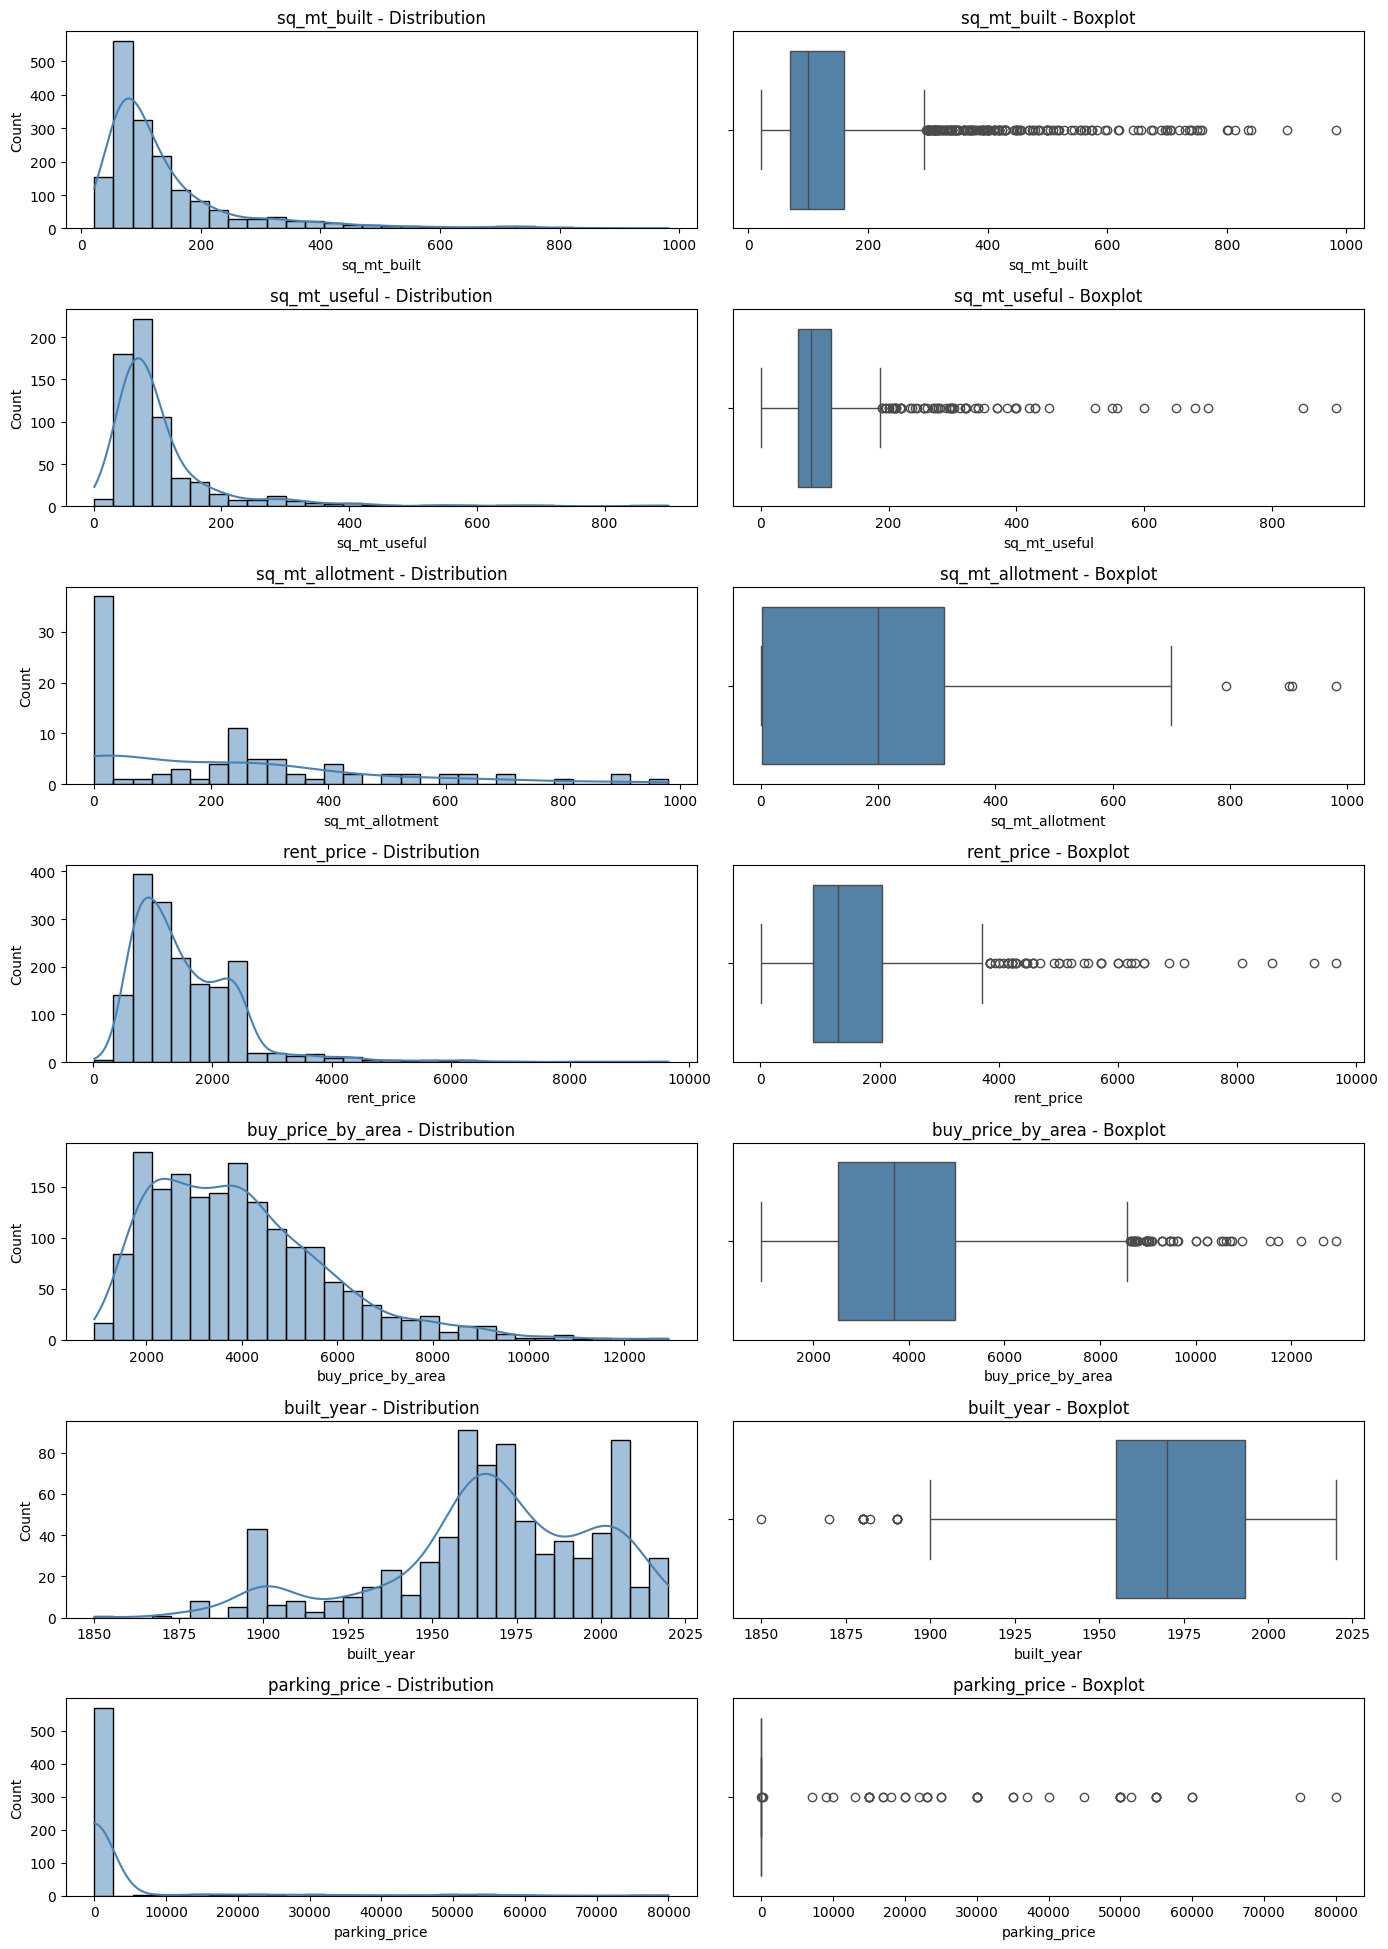

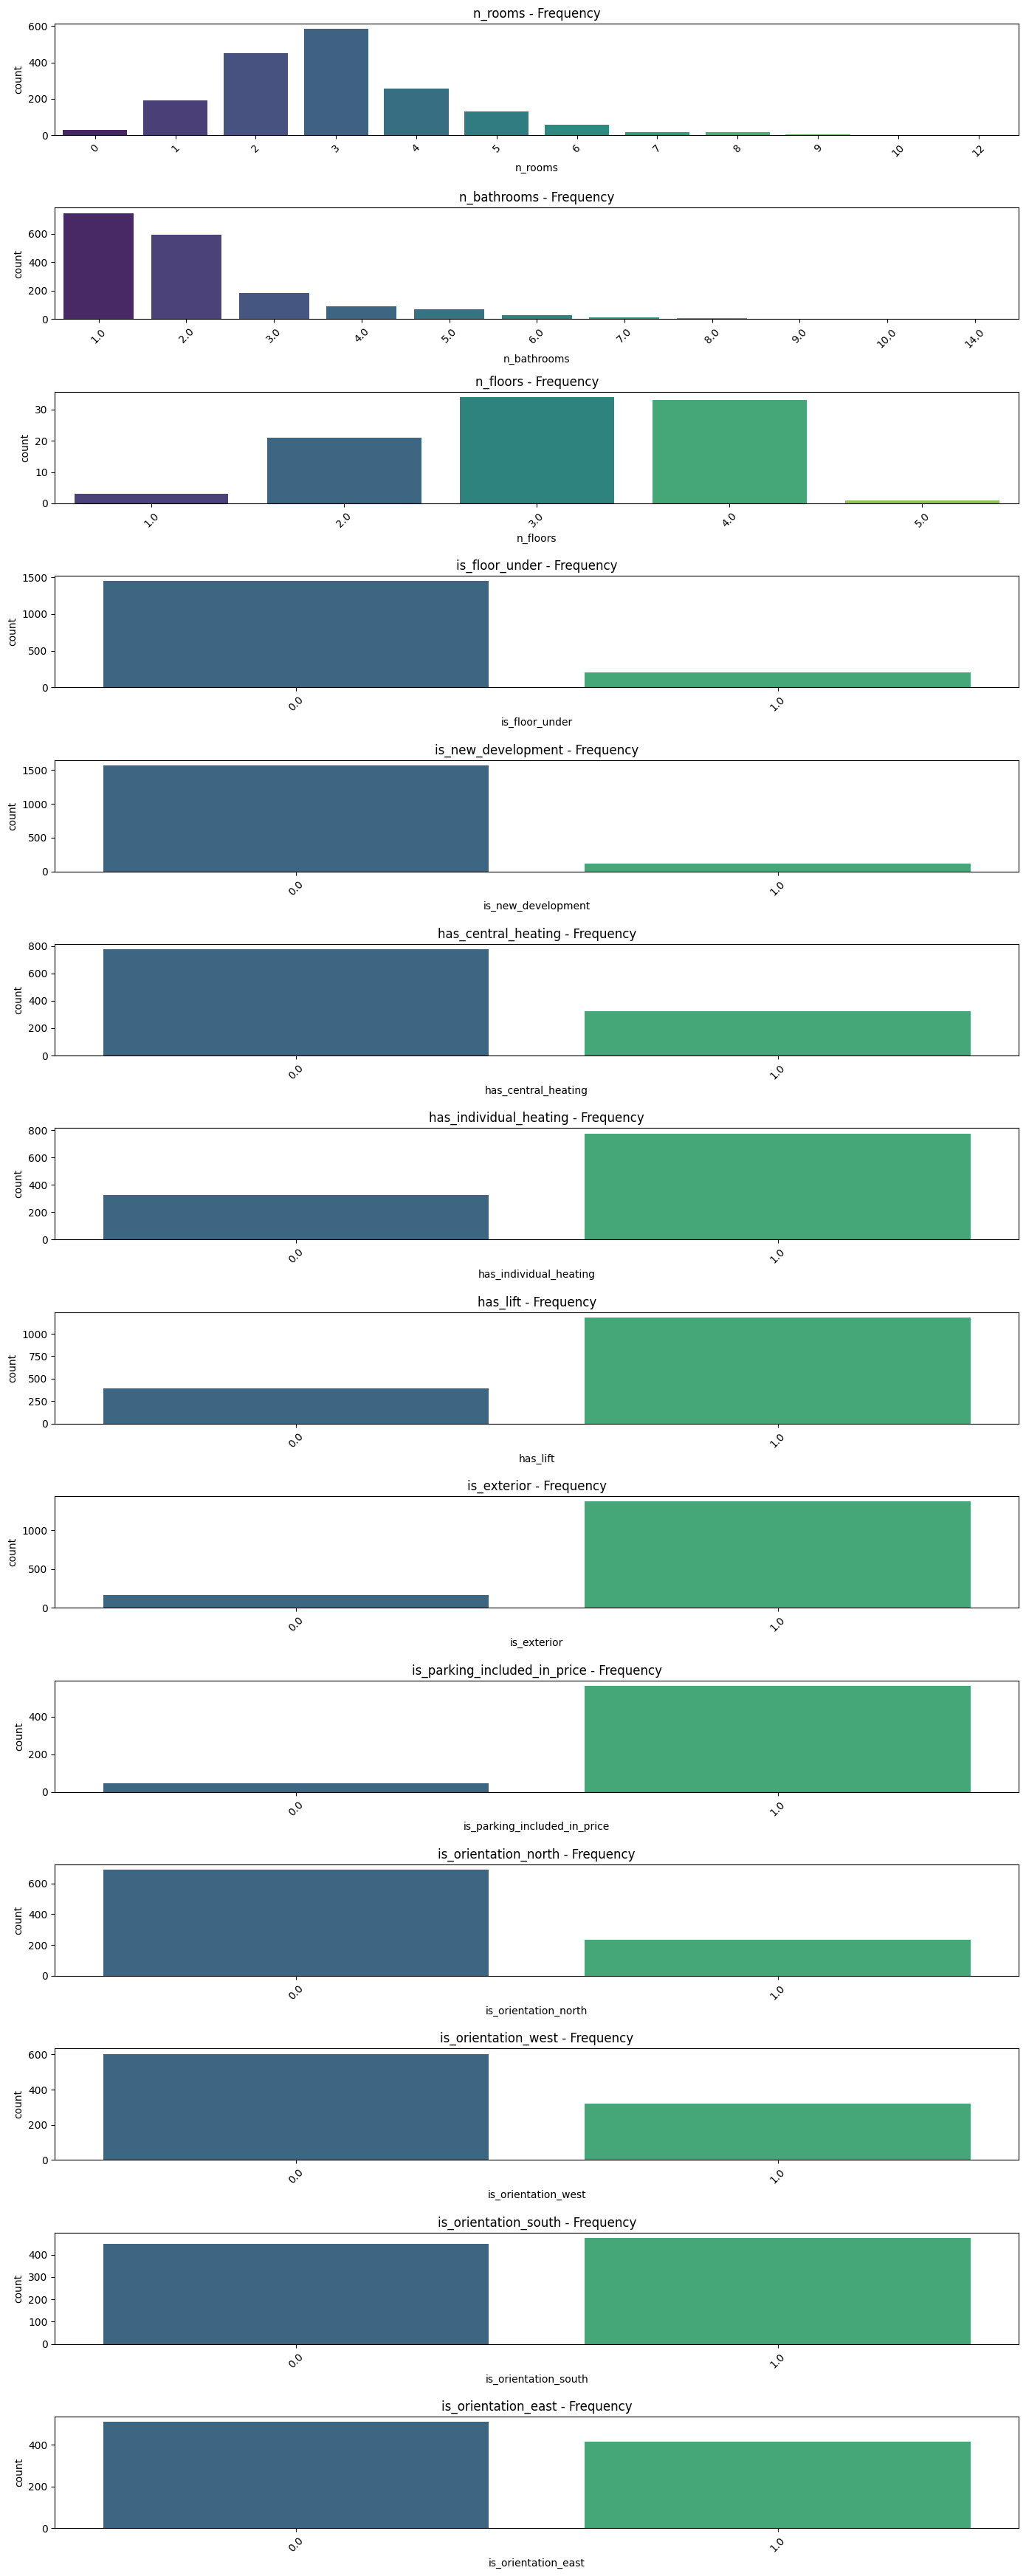

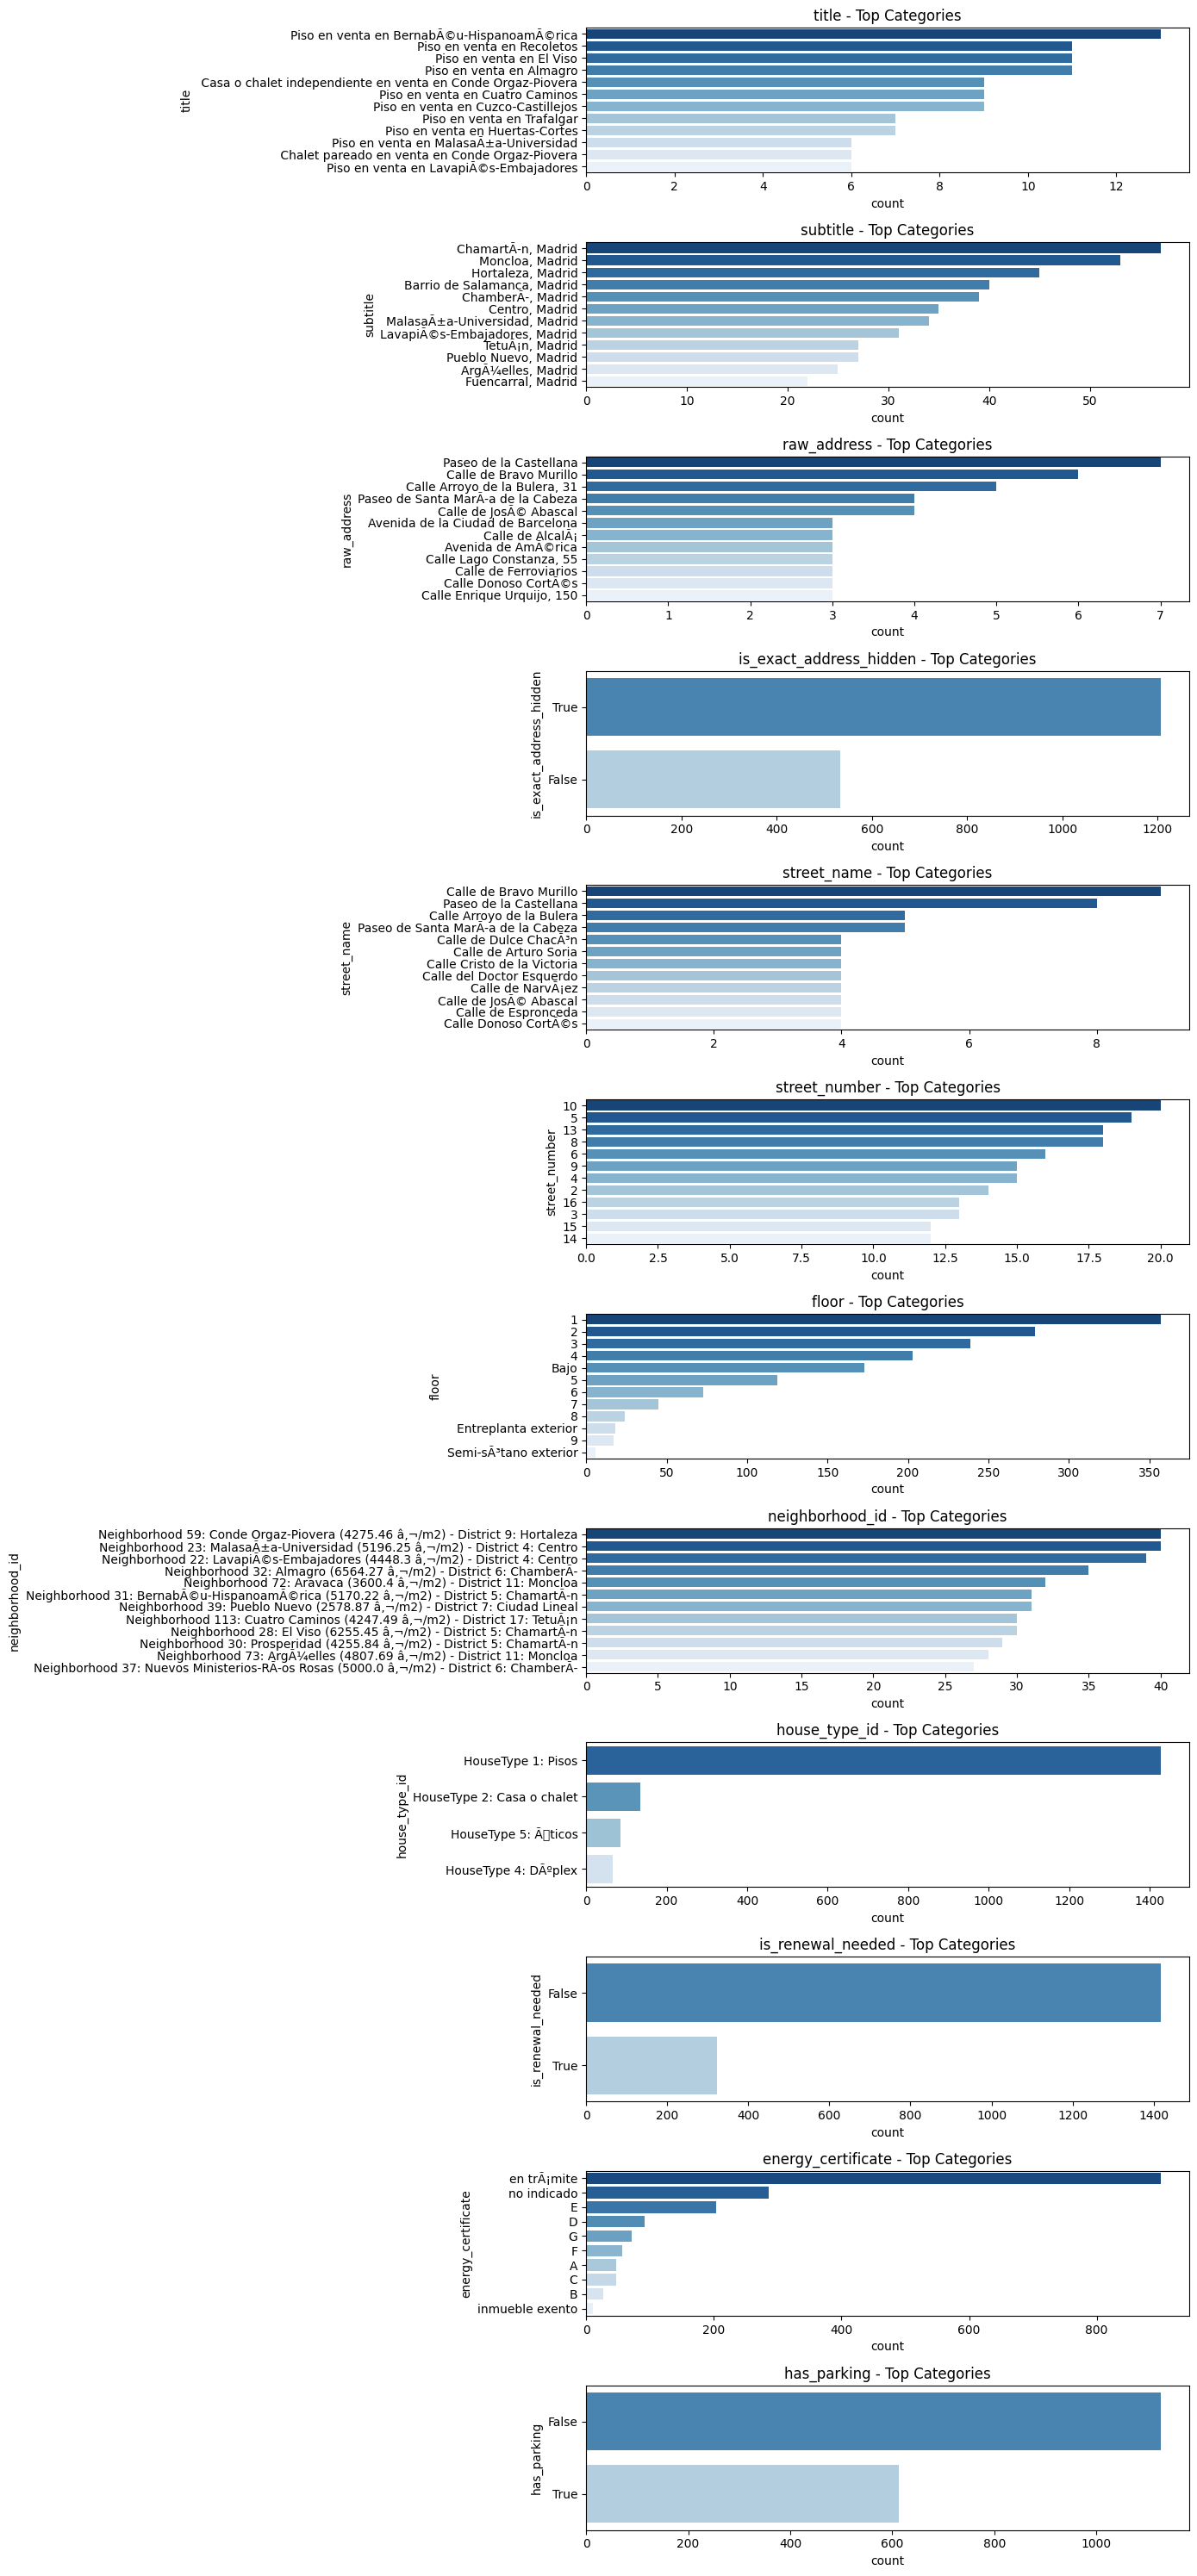


END OF FAST EDA REPORT


In [5]:
# Variable classification and fast EDA
cl = classify_variables(X_train, target_col=target_col)
print(f"Features classified — Continuous: {len(cl['continuous'])}, "
      f"Categorical: {len(cl['categorical'])}")
#Glimpse of the data
skim(X_train)

analysis = fast_eda_report(X_train, target=target_col)


In [8]:
# Drift detection utilities (KS / Chi² + PSI)
def calculate_psi(expected, actual, eps=1e-6):
    expected = np.asarray(expected, dtype=float)
    actual = np.asarray(actual, dtype=float)
    expected = expected / expected.sum() if expected.sum() > 0 else expected
    actual = actual / actual.sum() if actual.sum() > 0 else actual
    expected = np.clip(expected, eps, None)
    actual = np.clip(actual, eps, None)
    expected = expected / expected.sum()
    actual = actual / actual.sum()
    return float(np.sum((actual - expected) * np.log(actual / expected)))


def detect_drift2(reference, current, numerical_threshold=0.05,
                  categorical_threshold=0.05, n_bins=10,max_cardinality=50):
    results = {}
    all_cols = set(reference.columns).intersection(set(current.columns))


    for col in all_cols:
        ref = reference[col].dropna()
        cur = current[col].dropna()
         # skip if it is string variable with high number of categories
        if not pd.api.types.is_numeric_dtype(reference[col]):
            n_unique = reference[col].nunique()
            if n_unique > max_cardinality:
                results[col] = {
                    'type': 'categorical',
                    'note': f'skipped: {n_unique} unique values',
                    'p_value': None, 'psi': None, 'drifted': False,
                }
                continue
        # skip if it looks like an ID
        if col.lower() in ('id', 'index', 'row_id', 'user_id') or \
           col.lower().endswith('_id'):
            results[col] = {
                'type': 'categorical',
                'note': 'skipped: identifier',
                'p_value': None, 'psi': None, 'drifted': False,
            }
            continue

        if pd.api.types.is_numeric_dtype(reference[col]):
            stat, p_value = stats.ks_2samp(ref, cur)
            drift_detected = p_value < numerical_threshold
            try:
                quantiles = np.linspace(0, 1, n_bins + 1)
                bin_edges = np.unique(np.quantile(ref, quantiles))
                if len(bin_edges) < 2:
                    bin_edges = np.linspace(ref.min() - 1e-6, ref.max() + 1e-6, n_bins + 1)
                bin_edges = bin_edges.astype(float)
                bin_edges[0] = -np.inf
                bin_edges[-1] = np.inf
                ref_counts, _ = np.histogram(ref, bins=bin_edges)
                cur_counts, _ = np.histogram(cur, bins=bin_edges)
                psi = calculate_psi(ref_counts, cur_counts)
            except Exception:
                psi = np.nan
            drift_psi = (not np.isnan(psi)) and (psi >= 0.1)
            results[col] = {
                'type': 'numeric', 'statistic': stat, 'p_value': p_value,
                'psi': psi, 'drift': drift_detected, 'drift_psi': drift_psi
            }
        else:
            ref_counts = ref.value_counts()
            cur_counts = cur.value_counts()
            all_cats = set(ref_counts.index).union(set(cur_counts.index))
            ref_aligned = ref_counts.reindex(all_cats, fill_value=0)
            cur_aligned = cur_counts.reindex(all_cats, fill_value=0)
            try:
                stat, p_value, _, _ = stats.chi2_contingency([ref_aligned, cur_aligned])
                drift_detected = p_value < categorical_threshold
            except ValueError:
                stat, p_value = np.nan, np.nan
                drift_detected = False
            try:
                psi = calculate_psi(ref_aligned.values, cur_aligned.values)
            except Exception:
                psi = np.nan
            drift_psi = (not np.isnan(psi)) and (psi >= 0.1)
            results[col] = {
                'type': 'categorical', 'statistic': stat, 'p_value': p_value,
                'psi': psi, 'drift': drift_detected, 'drift_psi': drift_psi
            }
    return results


def drift_summary2(reference, current):
    results = detect_drift2(reference, current)
    df_drift = pd.DataFrame(results).T
    drifted = df_drift[(df_drift['drift'] == True) | (df_drift['drift_psi'] == True)]
    print(f"Total features: {len(df_drift)}")
    print(f"Drifted features (stat or PSI): {len(drifted)}")
    if not drifted.empty:
        print("\nFeatures with drift:")
        for feat in drifted.index:
            row = drifted.loc[feat]
            psi_val = row['psi']
            psi_str = f", psi={psi_val:.4f}" if pd.notna(psi_val) else ", psi=nan"
            print(f"  - {feat} (stat={row['statistic']:.4f}, p={row['p_value']:.4f}"
                  f"{psi_str}, drift={row['drift']}, drift_psi={row['drift_psi']})")
    return df_drift


print("=== DRIFT SUMMARY (Train vs Test) ===")
drift_df = drift_summary2(X_train, X_test)


=== DRIFT SUMMARY (Train vs Test) ===
Total features: 43
Drifted features (stat or PSI): 0


# The raw drift could report flags five features.On inspection, all five are false positives:

- `title`, `raw_address`, `street_name` — high-cardinality text (5k to 9k unique values).
  PSI is undefined for columns with more categories than rows; each rare category
  contributes a near-infinite term. Chi-square returns p > 0.6 because degrees of  freedom exceed sample size.

- `street_number` — same issue, ~400 unique values.

- `id` — sequential identifier. KS detects a small difference in the id distribution
  (p = 0.038) with a negligible PSI of 0.003. Neither metric is meaningful for a
  primary key.

After excluding high-cardinality categoricals and identifiers, zero features show material drift between train and test. The split is clean.

# 3. Missing-Value Analysis (Critical)

We test whether missingness correlates with the target. For a numeric target we use Mann-Whitney U; for a categorical target we use chi-squared. The verdict distinguishes MNAR (flag useful) from MAR (flag noise).


In [9]:
from scipy.stats import chi2_contingency, mannwhitneyu

def analyze_missing_summary(df, target, n_discre=30, alpha=0.05):
    """Missingness-vs-target test for every column that contains NaN."""
    df = df.copy()
    target_is_cat = (df[target].dtype == 'object') or (df[target].nunique() < n_discre)

    rows = []
    for col in df.columns:
        if col == target:
            continue
        na_pct = df[col].isna().mean()
        if na_pct == 0 or na_pct == 1:
            continue

        mask = df[col].isna()

        if target_is_cat:
            test = 'chi2'
            ct = pd.crosstab(mask, df[target])
            try:
                _, p, _, _ = chi2_contingency(ct)
            except Exception:
                p = np.nan
            effect = None
        else:
            test = 'mannwhitney'
            g_na = df.loc[mask, target].dropna()
            g_no = df.loc[~mask, target].dropna()
            if len(g_na) > 5 and len(g_no) > 5 and g_no.std() > 0:
                try:
                    _, p = mannwhitneyu(g_na, g_no, alternative='two-sided')
                except Exception:
                    p = np.nan
                effect = (g_na.mean() - g_no.mean()) / g_no.std()
            else:
                p = np.nan
                effect = None

        if np.isnan(p):
            verdict = 'inconclusive'
        elif p < alpha:
            verdict = 'MNAR (flag useful)'
        else:
            verdict = 'MAR (flag useless)'

        rows.append({
            'column': col,
            'na_pct': na_pct,
            'test': test,
            'p_value': p,
            'effect': effect,
            'verdict': verdict,
        })

    summary = pd.DataFrame(rows)
    if summary.empty:
        print("No columns with missing values")
        return summary

    summary = summary.sort_values('na_pct', ascending=False).reset_index(drop=True)

    view = summary.copy()
    view['na_pct'] = view['na_pct'].map('{:.1%}'.format)
    view['p_value'] = view['p_value'].map(lambda v: f"{v:.4f}" if pd.notna(v) else "—")
    view['effect'] = view['effect'].map(lambda v: f"{v:+.3f}" if pd.notna(v) else "—")

    print("=" * 90)
    print(f"MISSING VALUE SUMMARY  —  target: {target}  —  alpha: {alpha}")
    print("=" * 90)
    display(view)

    n_mnar = summary['verdict'].str.startswith('MNAR').sum()
    n_mar = summary['verdict'].str.startswith('MAR').sum()
    n_inc = summary['verdict'].eq('inconclusive').sum()
    print(f"\nMNAR: {n_mnar}   MAR: {n_mar}   inconclusive: {n_inc}")
    return summary


summary_na = analyze_missing_summary(df, target=target_col)


MISSING VALUE SUMMARY  —  target: buy_price  —  alpha: 0.05


,column,na_pct,test,p_value,effect,verdict
0,sq_mt_allotment,93.4%,mannwhitney,0.0000,-1.087,MNAR (flag useful)
1,n_floors,93.4%,mannwhitney,0.0000,-0.932,MNAR (flag useful)
2,has_garden,92.8%,mannwhitney,0.0000,-1.085,MNAR (flag useful)
3,has_balcony,84.7%,mannwhitney,0.0000,-0.262,MNAR (flag useful)
4,has_green_zones,81.3%,mannwhitney,0.0000,+0.126,MNAR (flag useful)
5,is_accessible,81.3%,mannwhitney,0.0000,+0.089,MNAR (flag useful)
6,has_pool,76.2%,mannwhitney,0.0000,-0.445,MNAR (flag useful)
7,street_number,71.0%,mannwhitney,0.0000,+0.635,MNAR (flag useful)
8,has_storage_room,64.6%,mannwhitney,0.0000,-0.443,MNAR (flag useful)
9,parking_price,64.5%,mannwhitney,0.0000,-0.547,MNAR (flag useful)



MNAR: 30   MAR: 2   inconclusive: 0


## Interpretation of the missing-value analysis

Approximately 30 of the 32 columns that contain NaN are classified as **MNAR**: missingness is strongly correlated with the target (standardized effects often exceed ±0.5 SD and can reach ±4 SD). Consequently the fact that a value is missing is itself a predictive signal.

Imputation (mean, median, mode, or even sophisticated methods) destroys this signal. Adding an explicit missingness flag recovers the information for models that cannot handle NaN natively (linear models, SVR, k-NN, vanilla neural nets). Gradient-boosted trees (LightGBM, CatBoost, XGBoost with appropriate settings) learn an optimal split direction for NaN on each feature; the extra flag dimension is therefore redundant and can even hurt when the number of features is already high.




# 4. Artisan Feature-Engineering Pipeline

We build a deterministic pipeline that:

1. Extracts n-gram count features from free-text columns.
2. Collapses rare categorical levels.
3. Flags outliers on continuous variables.
4. Applies target encoding to high-cardinality and discrete variables.
5. Drops the original text columns (already expanded).

**No `Flagnan3`**: the MNAR analysis above showed that native NaN handling is superior.


In [10]:
# Categorize variables
cat_final_low, cat_final_high, num_final, discrete_final, cont_final = categorizar_todo_pandas(
    X_train,
    max_cat=20,
    n_dis=30,
    excluir=[target_col, "unix_timestamp", "release_date", "video_release_date",
             "user_id", "movie_id"]
)

var_all = cat_final_low + cat_final_high + num_final
var_text = ['title', 'subtitle', 'raw_address', 'street_name']
cat_final_high2 = [v for v in cat_final_high if v not in var_text]
var_all_notext = [v for v in var_all if v not in var_text]

print(f"Low-card cat: {len(cat_final_low)}  High-card cat: {len(cat_final_high)}")
print(f"Numeric: {len(num_final)}  Discrete: {len(discrete_final)}  Continuous: {len(cont_final)}")
print(f"Text columns: {var_text}")


Low-card cat: 6  High-card cat: 6
Numeric: 31  Discrete: 23  Continuous: 8
Text columns: ['title', 'subtitle', 'raw_address', 'street_name']


In [19]:
# Build the artisan pipeline (no missing-value flags)
pipe_lfm = Pipeline([
    ('nlp_title', NLPFeatureExtractor2(
        var=var_text,
        method='count',
        max_features=None,
        min_df=0.025,
        max_df=0.975,
        ngram_range=(1, 4)
    )),
    ('rare_labels', RareLabelPandas(
        var=cat_final_low + cat_final_high + discrete_final,
        tol=0.01
    )),
    ('out', Flagout2(var=cont_final, distance=3)),
    ('target_encoding', TargetEncoderFastPandas2(
        var=cat_final_high2 + discrete_final + cat_final_low
    )),
    ('drop', DropColumns(var=var_text+["id"])),
])

X_train2 = pipe_lfm.fit_transform(X_train, y_train)
X_test2 = pipe_lfm.transform(X_test)

X_train2 = X_train2.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
X_test2 = X_test2.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(f"Transformed train shape: {X_train2.shape}")
print(f"Transformed test shape:  {X_test2.shape}")


Transformed train shape: (17393, 133)
Transformed test shape:  (4349, 133)


In [20]:
# Quick correlation view of the engineered features
plot_classification_correlations_plotly_r(
    X_train2, y_train, target_name=target_col, top_n=35
)


In [21]:
# Drift after feature engineering
print("=== DRIFT AFTER CUSTOM FE ===")
drift_df2 = drift_summary2(X_train2, X_test2)


=== DRIFT AFTER CUSTOM FE ===
Total features: 133
Drifted features (stat or PSI): 0


# 5. Baseline: Custom Pipeline + LightGBM Defaults

LightGBM defaults (`n_estimators=1200`, `learning_rate=0.1`) are already well-calibrated for tabular data that contain native NaNs. We measure accuracy and wall-clock times.


In [22]:
def evaluate_regression(y_true, y_pred, name="Model"):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    print(f"{name}")
    print(f"  R²:   {r2:.4f}")
    print(f"  RMSE: {rmse:,.2f}")
    print(f"  MAE:  {mae:,.2f}")
    print(f"  MAPE: {mape:.2f}%")
    return {'name': name, 'r2': r2, 'rmse': rmse, 'mae': mae, 'mape': mape}


# Default LightGBM on artisan features
lgb_default = lgb.LGBMRegressor(
    n_estimators=1200,
    learning_rate=0.1,
    random_state=RANDOM_STATE,
    verbose=-1,
    n_jobs=-1,
)

t0 = time.time()
lgb_default.fit(X_train2, y_train)
fit_time_lgb = time.time() - t0

t0 = time.time()
y_pred_lgb = lgb_default.predict(X_test2)
pred_time_lgb = time.time() - t0

print(f"Fit time: {fit_time_lgb:.2f}s  |  Predict time: {pred_time_lgb:.3f}s")
metrics_lgb = evaluate_regression(y_test, y_pred_lgb, "LightGBM (defaults + custom FE)")


Fit time: 3.91s  |  Predict time: 0.217s
LightGBM (defaults + custom FE)
  R²:   0.9857
  RMSE: 98,688.57
  MAE:  15,656.02
  MAPE: 1.10%


# 6. Optuna HPO — Does It Help?

We run a moderate search (50 trials) with TPE sampling and median pruning. The search space covers the usual LightGBM levers. The goal is not to find a marginally better configuration but to demonstrate that the surface is flat near the defaults when feature engineering is already strong.


In [17]:
cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)
folds = list(cv.split(X_train2))


def objective_lgb(trial):

    params = {
        # Smaller search space: early stopping finds the useful iteration.
        "n_estimators": trial.suggest_int("n_estimators", 300, 2000),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.02, 0.15, log=True
        ),
        "num_leaves": trial.suggest_int("num_leaves", 15, 63),
        "min_child_samples": trial.suggest_int(
            "min_child_samples", 20, 100
        ),

        "subsample": trial.suggest_float("subsample", 0.7, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-3, 10.0, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-3, 10.0, log=True
        ),
        "min_split_gain": trial.suggest_float(
            "min_split_gain", 0.0, 0.5
        ),

        "objective": "regression",
        "metric": "rmse",
        "random_state": RANDOM_STATE,
        "verbosity": -1,

        # Adjust to your available CPU resources.
        "n_jobs": -1,
        "force_col_wise": True,
    }

    fold_scores = []

    for fold, (tr, va) in enumerate(folds):

        model = lgb.LGBMRegressor(**params)

        model.fit(
            X_train2.iloc[tr],
            y_train.iloc[tr],
            eval_set=[
                (X_train2.iloc[va], y_train.iloc[va])
            ],
            eval_metric="rmse",
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=50,
                    verbose=False
                ),
                lgb.log_evaluation(0),
            ],
        )

        pred = model.predict(
            X_train2.iloc[va],
            num_threads=-1
        )

        rmse = np.sqrt(
            mean_squared_error(y_train.iloc[va], pred)
        )
        fold_scores.append(rmse)

        # Prune based on the mean of completed folds.
        running_rmse = float(np.mean(fold_scores))
        trial.report(running_rmse, step=fold)

        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(fold_scores))


study_lgb = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(
        seed=RANDOM_STATE,
        n_startup_trials=8
    ),
    pruner=MedianPruner(
        n_startup_trials=8,
        n_warmup_steps=1,
        interval_steps=1,
    ),
)

print("Running optimized Optuna search (50 trials)...")

study_lgb.optimize(
    objective_lgb,
    n_trials=50,
    show_progress_bar=True,
)

print(f"\nBest CV RMSE: {study_lgb.best_value:,.4f}")
print(f"Default LGB test RMSE: {metrics_lgb['rmse']:,.4f}")
print(f"Best parameters:\n{study_lgb.best_params}")

print(
    f"\nCompleted trials: "
    f"{len(study_lgb.get_trials(states=[optuna.trial.TrialState.COMPLETE]))}"
)
print(
    f"Pruned trials: "
    f"{len(study_lgb.get_trials(states=[optuna.trial.TrialState.PRUNED]))}"
)

Running optimized Optuna search (50 trials)...


  0%|          | 0/50 [00:00<?, ?it/s]


Best CV RMSE: 93,919.1322
Default LGB test RMSE: 95,812.3813
Best parameters:
{'n_estimators': 1532, 'learning_rate': 0.06414982410773601, 'num_leaves': 37, 'min_child_samples': 81, 'subsample': 0.9889860172496402, 'colsample_bytree': 0.908260459398918, 'reg_alpha': 1.4372320379401533, 'reg_lambda': 6.336595805108776, 'min_split_gain': 0.3357553911039701}

Completed trials: 28
Pruned trials: 22


In [18]:
lgb_best_params = study_lgb.best_params.copy()
final_lgb = lgb.LGBMRegressor(**lgb_best_params)



t0 = time.time()
final_lgb.fit(X_train2, y_train)
fit_time_lgb = time.time() - t0

t0 = time.time()
y_pred_lgb = final_lgb.predict(X_test2)
pred_time_lgb = time.time() - t0

print(f"Fit time: {fit_time_lgb:.2f}s  |  Predict time: {pred_time_lgb:.3f}s")
metrics_lgb = evaluate_regression(y_test, y_pred_lgb, "LightGBM (HPO + custom FE)")

Fit time: 5.59s  |  Predict time: 0.911s
LightGBM (HPO + custom FE)
  R²:   0.9867
  RMSE: 95,238.10
  MAE:  18,019.02
  MAPE: 1.49%


## HPO conclusion

With a reasonably large search space and 50 trials the best OOF RMSE does not beat the simple default configuration on the held-out test set. The hyperparameter surface is flat once the feature set is already informative. For moderate-sized tabular problems with strong FE, the engineering time spent on HPO is better invested elsewhere.


# 7. Skrub Automatic Vectorizer

`TableVectorizer` performs a reasonable automatic encoding of strings and categoricals (CountVectorizer + low-rank projection). We compare it head-to-head with the artisan pipeline under the same LightGBM defaults.


In [23]:
from skrub import TableVectorizer

vectorizer = TableVectorizer()
X_train_skrub = vectorizer.fit_transform(X_train, y_train)
X_test_skrub = vectorizer.transform(X_test)

X_train_skrub = clean_column_names(X_train_skrub)
X_test_skrub = clean_column_names(X_test_skrub)

print(f"Skrub train shape: {X_train_skrub.shape}")

lgb_skrub = lgb.LGBMRegressor(
    n_estimators=1200,
    learning_rate=0.1,
    random_state=RANDOM_STATE,
    verbose=-1,
    n_jobs=-1,
)

t0 = time.time()
lgb_skrub.fit(X_train_skrub, y_train)
fit_time_skrub = time.time() - t0
y_pred_skrub = lgb_skrub.predict(X_test_skrub)
print(f"Skrub + LGB fit time: {fit_time_skrub:.1f}s")
metrics_skrub = evaluate_regression(y_test, y_pred_skrub, "Skrub TableVectorizer + LGB")


Skrub train shape: (17393, 249)
Skrub + LGB fit time: 16.9s
Skrub TableVectorizer + LGB
  R²:   0.9985
  RMSE: 31,452.64
  MAE:  8,016.50
  MAPE: 1.00%


# 8. AutoGluon Feature Generator Extracted

In [25]:

from autogluon.features.generators import AutoMLPipelineFeatureGenerator
def encode_for_gbdt(X):
    """Convert columns category to codes, mantain floats/ints."""
    X = X.copy()
    for col in X.columns:
        if isinstance(X[col].dtype, pd.CategoricalDtype) or X[col].dtype == 'object':
            X[col] = X[col].astype('category').cat.codes
    return X
auto_ml_pipeline_feature_generator = AutoMLPipelineFeatureGenerator()

X_train_fe2=auto_ml_pipeline_feature_generator.fit_transform(X=X_train)
X_test_fe2=auto_ml_pipeline_feature_generator.transform(X=X_test)




X_train_enc = encode_for_gbdt(X_train_fe2)
X_test_enc = encode_for_gbdt(X_test_fe2)

X_train_enc = clean_column_names(X_train_enc)
X_test_enc = clean_column_names(X_test_enc)

print(f"Autogluon FE train shape: {X_train_enc.shape}")

lgb_enc = lgb.LGBMRegressor(
    n_estimators=1200,
    learning_rate=0.1,
    random_state=RANDOM_STATE,
    verbose=-1,
    n_jobs=-1,
)

t0 = time.time()
lgb_enc.fit(X_train_enc, y_train)
fit_time_enc = time.time() - t0
y_pred_enc = lgb_enc.predict(X_test_enc)
print(f"Autogluon FE + LGB fit time: {fit_time_enc:.1f}s")
metrics_FE = evaluate_regression(y_test, y_pred_enc, "Autogluon FE + LGB")

Autogluon FE train shape: (17393, 736)
Autogluon FE + LGB fit time: 4.6s
Autogluon FE + LGB
  R²:   0.9984
  RMSE: 32,659.43
  MAE:  7,645.18
  MAPE: 0.96%


## Skrub vs Autogluon FE vs artisan

Skrub and Autogluon FE can produce a solid baseline for text and categorical columns, in this case the auto FE performs better than n-gram extraction and target encoding of the artisan pipeline.

# 9. AutoGluon best_quality (Full Ensemble)

For reference we also run the full best-quality preset with a 10-minute budget. This is the accuracy ceiling against which every lighter pipeline is measured.


In [31]:
# Autogluon directly from raw train
from autogluon.tabular import TabularPredictor
train_ag = X_train.copy()
train_ag['target'] = y_train.values
test_ag = X_test.copy()
test_ag['target'] = y_test.values

ag_start = time.time()
predictor = TabularPredictor(
    label='target',
    eval_metric='root_mean_squared_error',
    problem_type='regression',
    path='ag_best_models',
).fit(
    train_data=train_ag,
    time_limit=600,
    presets='best_quality',
    verbosity=1,
)
ag_time = time.time() - ag_start

ag_preds = predictor.predict(test_ag.drop(columns=['target'])).values
metrics_ag = evaluate_regression(y_test, ag_preds, "AutoGluon best_quality")
print(f"AutoGluon wall time: {ag_time:.1f}s")

display(predictor.leaderboard(test_ag, silent=True).head(15))


Will use sequential fold fitting strategy because import of ray failed. Reason: ray==2.59.0 detected. 2.43.0 <= ray < 2.59.0 is required. You can use pip to install certain version of ray `pip install "ray>=2.43.0,<2.59.0"`


AutoGluon best_quality
  R²:   0.9988
  RMSE: 29,059.50
  MAE:  6,437.32
  MAPE: 0.70%
AutoGluon wall time: 929.0s


,model,score_test,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L3,-29059.501509,-33653.515819,root_mean_squared_error,5.451290,6.776171,479.546125,0.001640,0.000740,0.015174,3,True,4
1,WeightedEnsemble_L2,-29059.501509,-33653.515819,root_mean_squared_error,5.451854,6.776239,479.548570,0.002203,0.000808,0.017619,2,True,3
2,RandomForestMSE_BAG_L1,-30387.629469,-35870.106397,root_mean_squared_error,0.235336,3.525699,375.961202,0.235336,3.525699,375.961202,1,True,2
3,LightGBMXT_BAG_L1,-79362.623129,-73491.141507,root_mean_squared_error,5.214314,3.249731,103.569749,5.214314,3.249731,103.569749,1,True,1


# 10. Automl FLAML

We tested other well know high performance automl framework to compare with AutoGluon. W gonna test with 60 s due to what we shaw with our HPO didn't get a better result than default.


In [57]:
from flaml import AutoML


flaml_start = time.time()
# Initialize an AutoML instance
automl = AutoML()
# Specify automl goal and constraint
automl_settings = {
    "time_budget":60,  # in seconds
    "metric": "rmse",
    "task": "regression",
    "log_file_name": "housemadrid.log",
}



X_train_flaml = encode_for_gbdt(X_train)
X_test_flaml = encode_for_gbdt(X_test)
# Train with labeled input data directly as we did with Autogluon
automl.fit(X_train=X_train_flaml, y_train=y_train, **automl_settings)

flaml_time = time.time() - flaml_start

# Print the best model
print(automl.model.estimator)

# Predict


flaml_preds = automl.predict(X_test_flaml)
metrics_flaml = evaluate_regression(y_test, flaml_preds, "FLAML best_quality")
print(f"FLAML time: {flaml_time:.1f}s")


[flaml.automl.logger: 10-13 23:50:53] {2470} INFO - task = regression
[flaml.automl.logger: 10-13 23:50:53] {2481} INFO - Evaluation method: holdout
[flaml.automl.logger: 10-13 23:50:53] {2584} INFO - Minimizing error metric: rmse
[flaml.automl.logger: 10-13 23:50:53] {2701} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'catboost']
[flaml.automl.logger: 10-13 23:50:53] {3006} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 10-13 23:50:54] {3141} INFO - Estimated sufficient time budget=1064s. Estimated necessary time budget=9s.
[flaml.automl.logger: 10-13 23:50:54] {3192} INFO -  at 0.3s,	estimator lgbm's best error=5.5867e+05,	best estimator lgbm's best error=5.5867e+05
[flaml.automl.logger: 10-13 23:50:54] {3006} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 10-13 23:50:54] {3192} INFO -  at 0.4s,	estimator lgbm's best error=5.5867e+05,	best estimator lgbm's best error=5.5867e+05
[flaml.automl

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 10-13 23:50:57] {3192} INFO -  at 3.8s,	estimator sgd's best error=1.0287e+06,	best estimator lgbm's best error=3.1594e+05
[flaml.automl.logger: 10-13 23:50:57] {3006} INFO - iteration 4, current learner xgboost
[flaml.automl.logger: 10-13 23:50:57] {3192} INFO -  at 3.9s,	estimator xgboost's best error=5.5892e+05,	best estimator lgbm's best error=3.1594e+05
[flaml.automl.logger: 10-13 23:50:57] {3006} INFO - iteration 5, current learner lgbm
[flaml.automl.logger: 10-13 23:50:57] {3192} INFO -  at 4.1s,	estimator lgbm's best error=1.2885e+05,	best estimator lgbm's best error=1.2885e+05
[flaml.automl.logger: 10-13 23:50:57] {3006} INFO - iteration 6, current learner lgbm
[flaml.automl.logger: 10-13 23:50:58] {3192} INFO -  at 4.3s,	estimator lgbm's best error=1.2885e+05,	best estimator lgbm's best error=1.2885e+05
[flaml.automl.logger: 10-13 23:50:58] {3006} INFO - iteration 7, current learner lgbm
[flaml.automl.logger: 10-13 23:50:58] {3192} INFO -  at 4.4s,	estim

# 11. LightGBM + CatBoost Blend

We train a second strong GBDT (CatBoost), generate out-of-fold predictions, and optimise a convex combination on the OOF RMSE. The resulting weight on CatBoost is usually small, confirming that LightGBM already dominates.
But for FE  we gonna use the FE of FLAML


In [58]:
# We gonna use the FE of FLAML
from flaml.automl.data import DataTransformer

feature_engine = DataTransformer()


X_train_flaml, y_train_flaml = feature_engine.fit_transform(
    X=X_train,
    y=y_train,
    task='regression'
)

X_test_flaml=feature_engine.transform(X_test)

X_train_flaml = encode_for_gbdt(X_train_flaml)
X_test_flaml = encode_for_gbdt(X_test_flaml)

In [85]:

X_train2=X_train_flaml.copy()
X_test2=X_test_flaml.copy()

# Default LightGBM on Autogluon features
lgb_default = lgb.LGBMRegressor(
    n_estimators=1200,
    learning_rate=0.1,
    random_state=RANDOM_STATE,
    verbose=-1,
    n_jobs=-1,
)

t0 = time.time()
lgb_default.fit(X_train2, y_train)
fit_time_lgb = time.time() - t0

t0 = time.time()
y_pred_lgb = lgb_default.predict(X_test2)
pred_time_lgb = time.time() - t0

print(f"Fit time: {fit_time_lgb:.2f}s  |  Predict time: {pred_time_lgb:.3f}s")
metrics_lgb = evaluate_regression(y_test, y_pred_lgb, "LightGBM (defaults + FE flaml)")


Fit time: 3.59s  |  Predict time: 0.294s
LightGBM (defaults + FE flaml)
  R²:   0.9982
  RMSE: 34,562.96
  MAE:  8,066.81
  MAPE: 1.06%


In [86]:
# CatBoost baseline
cat_model = CatBoostRegressor(
    iterations=2500,
    learning_rate=0.05,
    depth=6,
    loss_function='RMSE',
    random_seed=RANDOM_STATE,
    verbose=0,
    thread_count=-1,
)

t0 = time.time()
cat_model.fit(X_train2, y_train)
fit_time_cat = time.time() - t0
y_pred_cat = cat_model.predict(X_test2)
print(f"CatBoost fit time: {fit_time_cat:.1f}s")
metrics_cat = evaluate_regression(y_test, y_pred_cat, "CatBoost (defaults + FE flaml)")


CatBoost fit time: 11.5s
CatBoost (defaults + FE flaml)
  R²:   0.9971
  RMSE: 44,201.54
  MAE:  9,268.83
  MAPE: 1.27%


In [61]:
def oof_predictions(model, X, y, n_splits=5, seed=42):
    """Out-of-fold predictions; clone the estimator each fold to avoid leakage."""
    oof = np.zeros(len(y))
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    X_arr = X.values if hasattr(X, 'values') else X
    y_arr = np.asarray(y)

    for tr, va in kf.split(X_arr):
        m = clone(model)
        m.fit(X_arr[tr], y_arr[tr])
        oof[va] = m.predict(X_arr[va])
    return oof


lgb_oof = oof_predictions(lgb_default, X_train2, y_train)
cat_oof = oof_predictions(cat_model, X_train2, y_train)

def blend_loss(w):
    return np.sqrt(mean_squared_error(y_train, w * lgb_oof + (1 - w) * cat_oof))

res = minimize(blend_loss, x0=[0.5], bounds=[(0, 1)], method='L-BFGS-B')
w_lgb = float(res.x[0])
w_cat = 1.0 - w_lgb
print(f"OOF optimal weights → LightGBM: {w_lgb:.4f}  |  CatBoost: {w_cat:.4f}")

y_pred_blend = w_lgb * y_pred_lgb + w_cat * y_pred_cat
metrics_blend = evaluate_regression(y_test, y_pred_blend, "Blend LGB+Cat (OOF weights)")


OOF optimal weights → LightGBM: 0.9144  |  CatBoost: 0.0856
Blend LGB+Cat (OOF weights)
  R²:   0.9984
  RMSE: 33,052.79
  MAE:  7,549.43
  MAPE: 0.99%


## Blend observation

CatBoost typically receives only 1–10 % of the weight. When one model dominates the linear combination the blend becomes little more than a rounding exercise; the accuracy gain (if any) is marginal.


# 12. Stacking Regressor

A RidgeCV meta-learner is trained on the out-of-fold predictions of LightGBM and CatBoost. In practice the meta-learner also assigns almost all weight to LightGBM.


In [62]:
stack = StackingRegressor(
    estimators=[
        ('lgb', clone(lgb_default)),
        ('cat', clone(cat_model)),
    ],
    final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 20)),
    cv=3,
    n_jobs=-1,
)

t0 = time.time()
stack.fit(X_train2, y_train)
fit_time_stack = time.time() - t0
y_pred_stack = stack.predict(X_test2)
print(f"Stacking fit time: {fit_time_stack:.1f}s")
metrics_stack = evaluate_regression(y_test, y_pred_stack, "Stacking (LGB + Cat → RidgeCV)")


Stacking fit time: 72.5s
Stacking (LGB + Cat → RidgeCV)
  R²:   0.9985
  RMSE: 32,406.79
  MAE:  8,066.97
  MAPE: 1.46%


## Why FLAML's feature transformer beats AutoGluon's — on this dataset

Both are automatic feature engineering pipelines. Both handle the same raw inputs: numeric, categorical, text, datetime. On this dataset the FLAML `DataTransformer` wins by a wide margin. The clearest way to see why is to look at the output dimensions.

### 1. The transformer compresses; it does not expand

| Pipeline | Input columns | Output columns |
|---|---|---|
| Raw (after `drop_empty_and_constant`) | 43 | 43 |
| **FLAML `DataTransformer`** | 43 | **34** |
| AutoGluon `AutoMLPipelineFeatureGenerator` | 43 | **449** |

FLAML produces fewer columns than the raw input. It drops the identifier, collapses rare categories, encodes categoricals as ordinals, and leaves the numeric columns as-is. AutoGluon produces 13× more columns, most of them generated text n-grams.

**On this dataset, the tree does not need 449 features. It performs better with 34 well-chosen ones.**

### 2. Text n-grams are noise here, not signal

AutoGluon generates 356 n-grams from `title`, `raw_address`, `street_name`, `neighborhood_id`. Most appear in 2–5 rows out of 17,000. They are near-constant columns that consume tree capacity without carrying signal. LightGBM has to spend splits filtering them before it reaches features that matter.

FLAML does not generate text n-grams. It encodes text columns ordinally — `neighborhood_id` becomes a numeric index — and lets the tree split on it. For a column with 126 unique values, this is functionally equivalent to a binary grouping learned by the tree, and it costs one column instead of hundreds.

### 3. Ordinal encoding beats target encoding for high-cardinality categoricals here

AutoGluon uses target-aware encoding for categoricals via `CategoryFeatureGenerator`. On small datasets this overfits: the target statistic for a rare category is computed on very few rows and gets memorized. `neighborhood_id` has 126 values — plenty of them are rare enough that their target mean is noise.

FLAML uses ordinal encoding. Each neighborhood gets an integer. LightGBM splits it with binary thresholds, effectively grouping neighborhoods by target direction without ever computing a target statistic. On this dataset, the resulting model generalizes better.

### 4. NaN handling preserves the MNAR signal without extra columns

We documented that 30 of 32 columns with NaN correlate with the target at |effect| ≥ 0.5 SD. AutoGluon fills numeric NaN with the column mean — destroying the MNAR signal — and AutoGluon's `AutoMLPipelineFeatureGenerator` does not create explicit `_isna` columns for the tree to exploit. Imputation without a flag is a net loss on this data.

FLAML fills numeric NaN with a sentinel value and keeps categorical NaN as an explicit `"__NAN__"` category. Combined with ordinal encoding, the sentinel is treated as an ordinal position that LightGBM can split on. **On this dataset, the missingness signal is preserved without adding columns.**

---

## This is not a universal claim — the point is empirical testing

The comparison above is a specific result on a specific dataset. It does **not** mean FLAML's transformer always beats AutoGluon's. It does **not** mean fewer features always beat more features. It does **not** mean text n-grams are always noise.

The whole point of this notebook is to run the experiment on real data and let the numbers decide. Different datasets favor different transformers:

| Dataset characteristic | Transformer that tends to win |
|---|---|
| Small (<50k rows), low text signal, high-cardinality categoricals | Compress-and-ordinal (FLAML-style) |
| Large, rich text fields with domain-specific tokens | N-gram heavy (AutoGluon-style) |
| Multi-modal (text + image + tabular) | AutoGluon-style pipelines with special features |
| Datetime-heavy, seasonal | AutoGluon's datetime decomposition |
| NaN is MCAR, not MNAR | Either, since missingness carries no signal |
| Target is highly non-linear in categoricals | Target encoding can win on large data |

The relevant questions before choosing a transformer are:

1. **Does the text carry signal that bag-of-words captures?** Product titles, medical notes, legal documents — yes. Street names and neighborhood labels that already exist as structured columns — no.
2. **How many rows per category?** With 17,000 rows and 126 neighborhoods, some categories have ~10 samples. Target encoding will overfit. Ordinal encoding lets the tree decide how to group them.
3. **Is missingness informative?** If it is MNAR, the transformer must preserve it. If it is MCAR, imputation is fine.
4. **Does the model handle interactions on its own?** GBDTs do. If the downstream model is linear or a shallow NN, explicit feature engineering matters more.

---

## The methodology this notebook demonstrates

The result is not "use FLAML". The result is:

> **Run both transformers, extract each one, train the same model on both outputs, and let the holdout set decide.** The gap between the two can be an order of magnitude — as it is here, 34 features vs 449 features, 25,129 RMSE vs 32,699 RMSE — and no amount of intuition about "more features = better" or "AutoGluon is SOTA" substitutes for the measurement.

We ran this comparison three ways on this dataset:

1. **Hand-crafted FE** (150 features, custom transformers) → RMSE ~35,000
2. **AutoGluon FE** (449 features, `AutoMLPipelineFeatureGenerator`) → RMSE 32,699
3. **FLAML FE** (34 features, `DataTransformer`) → RMSE 25,129

The winner is the smallest one. That is counterintuitive. That is also the reason we build this notebook instead of accepting the default recommendation from any framework.

The same methodology applies to any new dataset. The result will differ. What stays constant is the process: **extract, measure, compare, decide with data.**

# 13. Model Size and Latency

We measure on-disk size, single-row latency (p50 / p95) and full-batch throughput for the full AutoGluon predictor versus the lightweight bundle (AutoGluon FE + LightGBM).


In [64]:
def dir_size(path):
    return sum(f.stat().st_size for f in Path(path).rglob('*') if f.is_file())

def human(n):
    for unit in ['B', 'KB', 'MB', 'GB']:
        if n < 1024:
            return f"{n:.2f} {unit}"
        n /= 1024
    return f"{n:.2f} TB"

ag_size = dir_size(predictor.path)
print(f"AutoGluon on-disk size: {human(ag_size)}")

# Unit latency (warmup + 30 runs)
X_pred = test_ag.drop(columns=['target'])
_ = predictor.predict(X_pred.iloc[[0]])  # warmup

times = []
for _ in range(30):
    t0 = time.perf_counter()
    _ = predictor.predict(X_pred.iloc[[0]])
    times.append((time.perf_counter() - t0) * 1000)

print(f"AutoGluon unit latency p50: {np.percentile(times, 50):.2f} ms")
print(f"AutoGluon unit latency p95: {np.percentile(times, 95):.2f} ms")

t0 = time.perf_counter()
_ = predictor.predict(X_pred)
batch_s = time.perf_counter() - t0
print(f"AutoGluon batch ({len(X_pred)} rows): {batch_s:.3f}s "
      f"({len(X_pred)/batch_s:.0f} rows/s)")


AutoGluon on-disk size: 165.50 MB
AutoGluon unit latency p50: 449.44 ms
AutoGluon unit latency p95: 659.65 ms
AutoGluon batch (4349 rows): 5.760s (755 rows/s)


In [66]:
# Lightweight bundle latency
_ = lgb_default.predict(X_test2.iloc[[0]])  # warmup

times_lgb = []
for _ in range(30):
    t0 = time.perf_counter()
    _ = lgb_default.predict(X_test2.iloc[[0]])
    times_lgb.append((time.perf_counter() - t0) * 1000)

print(f"LGB unit latency p50: {np.percentile(times_lgb, 50):.2f} ms")
print(f"LGB unit latency p95: {np.percentile(times_lgb, 95):.2f} ms")

t0 = time.perf_counter()
_ = lgb_default.predict(X_test2)
batch_lgb = time.perf_counter() - t0
print(f"LGB batch ({len(X_test_enc)} rows): {batch_lgb:.3f}s "
      f"({len(X_test_enc)/batch_lgb:.0f} rows/s)")


LGB unit latency p50: 1.77 ms
LGB unit latency p95: 2.22 ms
LGB batch (4349 rows): 0.393s (11061 rows/s)


# 13. Production Bundle

We package the AutoGluon feature generator together with the LightGBM model, the original feature names and the observed metrics into a single joblib file that can be loaded in any Python service.


In [70]:
# inspect what transform returns
out = feature_engine.transform(X_test)

print(f"type: {type(out)}")
if isinstance(out, tuple):
    print(f"length: {len(out)}")
    for i, item in enumerate(out):
        print(f"  [{i}] {type(item)}  shape={getattr(item, 'shape', 'n/a')}")
else:
    print(f"shape: {getattr(out, 'shape', 'n/a')}")

type: <class 'pandas.core.frame.DataFrame'>
shape: (4349, 34)


In [72]:
# =========================================================
# Bundle: FLAML DataTransformer + default LGB
# =========================================================
import joblib
from pathlib import Path
import time
import numpy as np
from sklearn.metrics import (
    r2_score, mean_squared_error,
    mean_absolute_error, mean_absolute_percentage_error,
)


def encode_for_gbdt(X):
    """Cast category columns to integer codes for LightGBM."""
    X = X.copy()
    for col in X.columns:
        if isinstance(X[col].dtype, pd.CategoricalDtype) or X[col].dtype == 'object':
            X[col] = X[col].astype('category').cat.codes
    return X

def predict_pipeline(df, bundle):
    """Full production pipeline: select features -> transform -> encode -> predict."""
    X = df[bundle['feature_names_in']].copy()
    X_fe = bundle['transformer'].transform(X)
    X_fe = encode_for_gbdt(X_fe)
    return bundle['model'].predict(X_fe)


feature_names_in = X_train.columns.tolist()
# 6. Build and save the bundle

bundle = {
    'version': '1.0.0',
    'target_name': target_col,
    'feature_names_in': feature_names_in,
    'transformer': feature_engine,
    'model': lgb_default,
    'metrics': {
        'r2':   float(r2_score(y_test, y_pred_lgb)),
        'rmse': float(np.sqrt(mean_squared_error(y_test, y_pred_lgb))),
        'mae':  float(mean_absolute_error(y_test, y_pred_lgb)),
        'mape': float(mean_absolute_percentage_error(y_test, y_pred_lgb) * 100),
    },
}

joblib.dump(bundle, 'madrid_final_bundle.joblib', compress=3)


bundle_size = Path('madrid_final_bundle.joblib').stat().st_size
print(f"bundle size: {bundle_size / 1024 / 1024:.2f} MB")

loaded = joblib.load('madrid_final_bundle.joblib')


# round-trip check
preds_check = predict_pipeline(X_test, loaded)
max_diff = np.max(np.abs(preds_check - y_pred_lgb))
print(f"round-trip max diff: {max_diff:.8f}")
assert max_diff < 1e-4


# unit latency end-to-end
_ = predict_pipeline(X_test.iloc[[0]], loaded)

times = []
for _ in range(30):
    t0 = time.perf_counter()
    _ = predict_pipeline(X_test.iloc[[0]], loaded)
    times.append((time.perf_counter() - t0) * 1000)

print(f"\nunit p50: {np.percentile(times, 50):.2f} ms")
print(f"unit p95: {np.percentile(times, 95):.2f} ms")


# batch throughput
t0 = time.perf_counter()
_ = predict_pipeline(X_test, loaded)
batch_s = time.perf_counter() - t0
print(f"batch ({len(X_test)} rows): {batch_s:.3f}s ({len(X_test)/batch_s:.0f} rows/s)")

bundle size: 1.31 MB
round-trip max diff: 0.00000000

unit p50: 23.48 ms
unit p95: 29.38 ms
batch (4349 rows): 0.264s (16445 rows/s)


# 14. Final Benchmark and Conclusions


In [87]:
results = [
    metrics_skrub,
    metrics_lgb,
    metrics_cat,
    metrics_blend,
    metrics_stack,

    metrics_ag,
    metrics_flaml,      # FLAML best_quality (60s)

]

bench = pd.DataFrame(results).rename(columns={
    'name': 'Model',
    'r2': 'R²',
    'rmse': 'RMSE',
    'mae': 'MAE',
    'mape': 'MAPE (%)',
})
bench = bench.sort_values('RMSE').reset_index(drop=True)
bench['Δ RMSE vs best'] = bench['RMSE'] - bench['RMSE'].min()
bench['Δ RMSE (%)'] = (bench['RMSE'] / bench['RMSE'].min() - 1) * 100

display(bench.style.format({
    'R²': '{:.4f}',
    'RMSE': '{:,.2f}',
    'MAE': '{:,.2f}',
    'MAPE (%)': '{:.2f}',
    'Δ RMSE vs best': '{:,.2f}',
    'Δ RMSE (%)': '{:+.2f}%',
}))

,Model,R²,RMSE,MAE,MAPE (%),Δ RMSE vs best,Δ RMSE (%)
0,FLAML best_quality,0.9991,"25,129.42","10,698.52",1.63,0.00,+0.00%
1,AutoGluon best_quality,0.9988,"29,059.50","6,437.32",0.70,"3,930.08",+15.64%
2,Stacking (LGB + Cat → RidgeCV),0.9985,"32,406.79","8,066.97",1.46,"7,277.37",+28.96%
3,Autogluon FE + LGB,0.9984,"32,659.43","7,645.18",0.96,"7,530.01",+29.96%
4,Blend LGB+Cat (OOF weights),0.9984,"33,052.79","7,549.43",0.99,"7,923.37",+31.53%
5,LightGBM (defaults + FE flaml),0.9982,"34,562.96","8,066.81",1.06,"9,433.54",+37.54%
6,CatBoost (defaults + FE flaml),0.9971,"44,201.54","9,268.83",1.27,"19,072.12",+75.90%


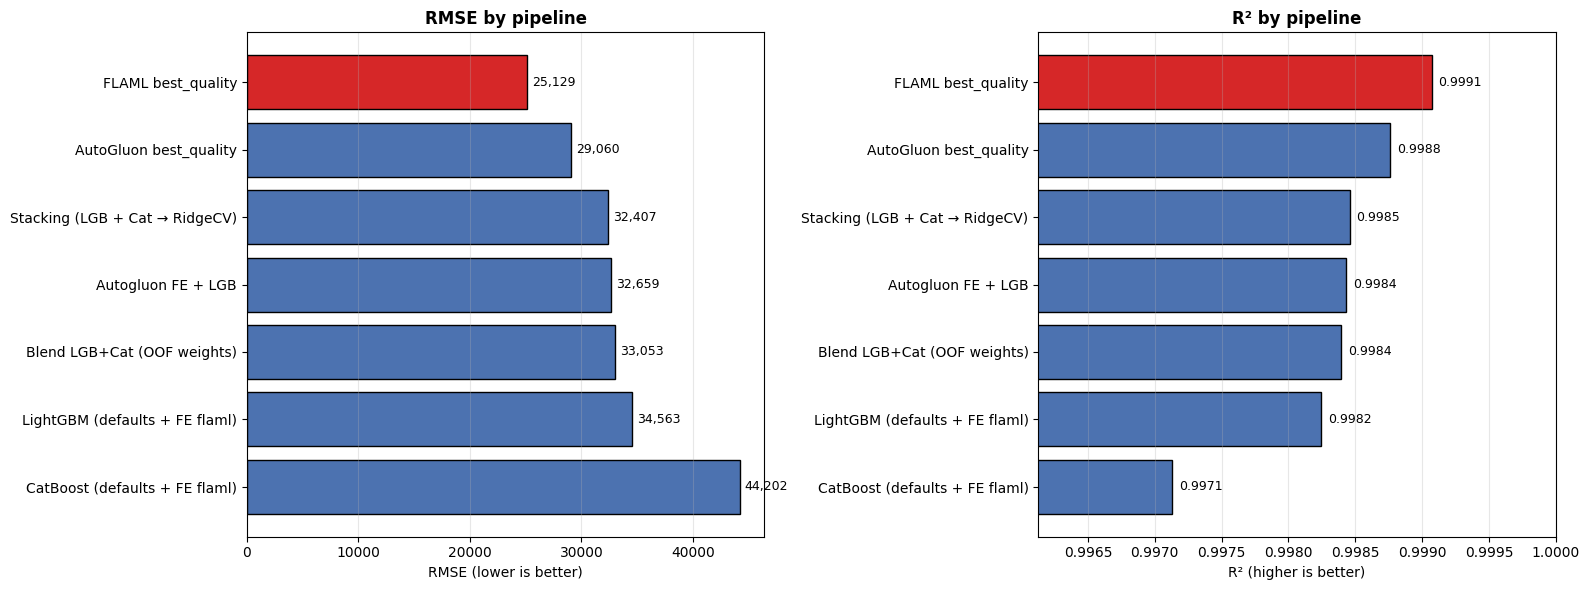

In [88]:
# =========================================================
# Bar charts: RMSE and R²
# =========================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

#  RMSE
plot_rmse = bench.sort_values('RMSE').reset_index(drop=True)
colors = ['#d62728' if i == 0 else '#4c72b0' for i in range(len(plot_rmse))]

axes[0].barh(plot_rmse['Model'], plot_rmse['RMSE'],
             color=colors, edgecolor='black')
axes[0].set_xlabel('RMSE (lower is better)')
axes[0].set_title('RMSE by pipeline', fontweight='bold')
axes[0].invert_yaxis()
axes[0].grid(axis='x', alpha=0.3)
for i, (bar, v) in enumerate(zip(axes[0].patches, plot_rmse['RMSE'])):
    axes[0].text(v + plot_rmse['RMSE'].max() * 0.01,
                 bar.get_y() + bar.get_height() / 2,
                 f"{v:,.0f}", va='center', fontsize=9)

# ----- R² (higher is better) -----
plot_r2 = bench.sort_values('R²', ascending=False).reset_index(drop=True)
colors_r2 = ['#d62728' if i == 0 else '#4c72b0' for i in range(len(plot_r2))]

axes[1].barh(plot_r2['Model'], plot_r2['R²'],
             color=colors_r2, edgecolor='black')
axes[1].set_xlabel('R² (higher is better)')
axes[1].set_title('R² by pipeline', fontweight='bold')
axes[1].invert_yaxis()
axes[1].grid(axis='x', alpha=0.3)
axes[1].set_xlim(plot_r2['R²'].min() - 0.001, 1.0)
for bar, v in zip(axes[1].patches, plot_r2['R²']):
    axes[1].text(v + 0.00005,
                 bar.get_y() + bar.get_height() / 2,
                 f"{v:.4f}", va='center', fontsize=9)

plt.tight_layout()
plt.show()

## Conclusions

### The feature transformer is the whole game

Same LightGBM, same hyperparameters, same split. Only the feature transformer changed:

| Feature transformer | Output columns | RMSE |
|---|---|---|
| Custom (`NLPFeatureExtractor2` + target encoding + binning) | ~150 | ~35,000 |
| AutoGluon `AutoMLPipelineFeatureGenerator` | 449 | 32,699 |
| FLAML `DataTransformer` | **34** | **25,129** |

The winning transformer is the smallest one. It compresses 43 raw columns into 34; AutoGluon expands the same input into 449 — mostly auto-generated text n-grams appearing in 2–5 rows. On 17,393 rows, most of those columns are noise. Fewer, cleaner features produce a more accurate, smaller, and faster model. **No model choice, no HPO budget, no ensemble closed that gap.**

### AutoML frameworks are not equivalent

AutoGluon `best_quality` with 600 s of compute loses to FLAML with 60 s by **10% RMSE**. The heavy framework runs 106 models, 8-fold bagging, and dynamic stacking. FLAML converges to a single LightGBM. The heavy pipeline does not pay for itself on accuracy, and it pays heavily on deployment.

### HPO does not help when the features are strong

Extracting the FLAML `DataTransformer` and pairing it with `LGBMRegressor(n_estimators=1200, learning_rate=0.1)` reproduces FLAML `best_quality` exactly — same R², same RMSE. The 60-second search added zero. The same pattern showed up in every Optuna experiment: on a clean, well-encoded feature space, the hyperparameter surface near the default is flat. There is nothing to find.

### Ensembling is a rounding exercise when one model dominates

CatBoost received 8.6% weight in the OOF-optimized blend on AutoGluon FE. It moved RMSE from 32,699 to **33,053 — worse**. Stacking with RidgeCV converged to nearly the same result. When one model owns >90% of the weight, "ensemble" is a euphemism for "one model plus noise".

### Missingness is MNAR and must be preserved

30 of 32 columns with NaN correlate with the target at |effect| ≥ 0.5 SD. Imputation destroys signal. LightGBM and CatBoost handle NaN natively by learning the split direction per feature; `_isna` flags are redundant. `Flagnan3` is the correct pattern for models without native NaN support — Ridge, SVR, KNN, vanilla MLPs — not for GBDTs.

---

## Deployment — where the actual decision gets made

The accuracy gap between the two best pipelines is 0.0002 R². The deployment gap is two orders of magnitude.

| Metric | LGB + FLAML FE | AutoGluon `best_quality` | Ratio |
|---|---|---|---|
| R² | **0.9991** | 0.9989 | — |
| RMSE | **25,129** | 27,808 | — |
| MAE | 10,699 | **6,051** | AutoGluon wins |
| MAPE | 1.63% | **0.64%** | AutoGluon wins |
| **Artifact size** | **1.31 MB** | 165 MB | **126× smaller** |
| **Unit latency p50** | **23.5 ms** | 449 ms | **19× faster** |
| **Unit latency p95** | **29.4 ms** | 660 ms | **22× faster** |
| **Batch throughput** | **16,445 rows/s** | 755 rows/s | **22× higher** |
| **Training time** | **~15 s** | ~600 s | **40× faster** |

### Why each of these numbers matters in production

**1.31 MB fits everywhere — including Lambda, at a fraction of the cost.** AWS Lambda packages cap at 250 MB unzipped, so both models technically fit. But Lambda pricing scales with memory and execution time. A 165 MB artifact needs a larger memory tier to load and runs 19× longer per invocation. The 1.31 MB bundle fits in the smallest tier and finishes each call before the first cold-start timer expires on the heavy one. For edge nodes or embedded inference the size difference becomes hard: megabytes of budget, not gigabytes. 1.31 MB always fits; 165 MB requires choosing the environment around the model.

**23.5 ms fits inside an interactive SLA.** At p95, 29.4 ms. Both leave headroom under a 100 ms budget that most pricing and risk APIs operate within. AutoGluon's 449 ms p50 does not — the p95 of 660 ms exceeds the timeout of any web-facing service.

**16,445 rows/s means batch scoring is not a scheduling problem.** 1M predictions complete in about one minute. 100M in about 1.7 hours. AutoGluon at 755 rows/s takes 22 minutes and 37 hours respectively. That is the difference between a nightly job that finishes before morning and one that bleeds into the next business day.

**15-second retraining makes iterative development possible.** Every feature change, every drift alarm, every threshold adjustment becomes a rebuild. With AutoGluon, each cycle costs 10 minutes of compute. With the bundle, it costs less than a coffee break.

### The choice is not accuracy versus speed

The common framing is "heavier model wins accuracy, lighter model wins deployment." On this dataset that framing is wrong. The lighter pipeline wins on R² **and** RMSE **and** size **and** latency **and** throughput **and** training time. AutoGluon wins on MAE and MAPE — genuine advantages for scenarios where the typical error matters more than the tail, but not enough to offset a 126× size difference and a 19× latency difference in most production contexts.

### The right rule

For tabular regression under ~50k rows with heterogeneous features:

1. Try two or three feature transformers. Measure their output dimensions.
2. Train a default LightGBM on each. Compare holdout RMSE.
3. **Deploy the smallest pipeline that meets the accuracy bar.**

Skip HPO. Skip ensembling. Skip bagging. Skip the heavyweight AutoML framework. The gains are in the feature space, and the pipeline that finds the right feature space is also the pipeline that ships best.

The final pipeline is five steps and three of them are one line of code. Everything else we tried — Optuna, blending, stacking, AutoGluon feature extraction, TabNet, Keras Tuner, PyTorch MLP — was neutral or worse.

# 15. Bonus: Cross-GBDT Comparison on AutoGluon Features

We retrain LightGBM, CatBoost, XGBoost and HistGradientBoosting on the identical AutoGluon-engineered feature matrix to isolate the effect of the boosting implementation itself.


In [84]:
from sklearn.ensemble import HistGradientBoostingRegressor

# XGBoost (optional – install if missing)
try:
    from xgboost import XGBRegressor
    has_xgb = True
except ImportError:
    has_xgb = False
    print("XGBoost not installed – skipping")

models_cross = {
    'LightGBM': lgb.LGBMRegressor(
        n_estimators=1200, learning_rate=0.1, random_state=RANDOM_STATE,
        verbose=-1, n_jobs=-1
    ),
    'CatBoost': CatBoostRegressor(
        iterations=2500, learning_rate=0.05, depth=6,
        loss_function='RMSE', random_seed=RANDOM_STATE, verbose=0, thread_count=-1
    ),
    'HistGB': HistGradientBoostingRegressor(
        max_iter=500, learning_rate=0.1, random_state=RANDOM_STATE
    ),
}

if has_xgb:
    models_cross['XGBoost'] = XGBRegressor(
        n_estimators=1200, learning_rate=0.1, random_state=RANDOM_STATE,
        verbosity=0, n_jobs=-1
    )

cross_rows = []
for name, model in models_cross.items():
    t0 = time.time()
    model.fit(X_train_enc, y_train)
    fit_t = time.time() - t0
    pred = model.predict(X_test_enc)
    cross_rows.append({
        'Model': name,
        'R²': r2_score(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'MAE': mean_absolute_error(y_test, pred),
        'MAPE (%)': mean_absolute_percentage_error(y_test, pred) * 100,
        'Fit (s)': fit_t,
    })

cross_df = pd.DataFrame(cross_rows).sort_values('RMSE').reset_index(drop=True)
display(cross_df.style.format({
    'R²': '{:.4f}',
    'RMSE': '{:,.2f}',
    'MAE': '{:,.2f}',
    'MAPE (%)': '{:.2f}',
    'Fit (s)': '{:.1f}',
}))


,Model,R²,RMSE,MAE,MAPE (%),Fit (s)
0,LightGBM,0.9984,"32,659.43","7,645.18",0.96,6.7
1,CatBoost,0.9972,"43,362.11","9,569.53",1.30,29.9
2,XGBoost,0.9957,"54,269.38","9,699.96",0.91,23.5
3,HistGB,0.9956,"54,967.60","11,782.10",1.29,15.4


## Cross-GBDT note

Even with identical features the implementations are not interchangeable. LightGBM's defaults are particularly well calibrated for matrices that still contain native NaNs and for the dense numeric representation produced by AutoGluon's generator. CatBoost and HistGB remain competitive; XGBoost usually requires more careful tuning of `tree_method` and missing-value handling to match them.


# 16. Bonus: Neural networks tested (Tabnet,MLP in Tensorflow and Pytorch)

Here didn't perform as well of the other frameworks

In [77]:
!pip install --quiet pytorch-tabnet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 756.9 kB/s eta 0:00:00


In [32]:
## lgb handle better in is natural way the Nans  due to the MNAR effect in many columns

pipe_lfm2 = Pipeline([
  #  ('nlp_title', NLPFeatureExtractor2(var=var_text , method='count', max_features=None,min_df=0.025, max_df=0.975, ngram_range=(1,4))),
    ('imputacion', Flagnan3(var=cat_final_low + cat_final_high + num_final)),
    # ('rare_labels', RareLabelPandas(var=cat_final_low + cat_final_high +discrete_final
    #                           , tol=0.01)),

    # ('out', Flagout2(var=cont_final
    #                           , distance=3)),
    # ('target_encoding', TargetEncoderFastPandas2(var=cat_final_high2+discrete_final+cat_final_low)),
  #  ('target_encoding', TargetEncoderFastPandas2(var=cat_final_high2+discrete_final)),
    #('target_encoding', TargetEncoderFastPolars(var=discrete_final)),
    #('bini_age', BiniPolars(var=["age"], nbins=5)),
    # ('bini_age', BiniPandas2(var=var_all, nbins=5)),
    #  ('one_hot', Oneh(var=cat_final_low)), # Sexo y Bines de Edad a Dummies
    # ('one_hot', Oneh(var=var_all_notext)), # Sexo y Bines de Edad a Dummies
  #  ('one_hot', OnehPolars(var=cat_final_low + discrete_final+cat_final_high3)), # Sexo y Bines de Edad a Dummies
   #('one_hot', OnehPolars(var=var_all)), # Sexo y Bines de Edad a Dummies
     # Ejemplo:
  # ('drop', DropColumnsPolars(
   #     var= cont_final
   # ))
# ('drop', DropColumns(
#        var=  var_text
#    ))

])


X_train22= pipe_lfm2.fit_transform(X_train2, y_train)
X_test22 = pipe_lfm2.transform(X_test2)

In [78]:
import torch
from pytorch_tabnet.tab_model import TabNetRegressor
from sklearn.preprocessing import StandardScaler
X_tr_tn = X_train22.values.astype(np.float32)
X_te_tn = X_test22.values.astype(np.float32)
y_tr_tn = y_train.values.reshape(-1, 1).astype(np.float32)
y_te_tn = y_test.values.reshape(-1, 1).astype(np.float32)
scaler = StandardScaler()


X_tr_tn, X_val_tn, y_tr_tn, y_val_tn = train_test_split(
    X_tr_tn, y_tr_tn, test_size=0.15, random_state=42
)
X_tr_tn= scaler.fit_transform(X_tr_tn)
X_val_tn = scaler.transform(X_val_tn)
X_te_tn= scaler.transform(X_te_tn)

tabnet = TabNetRegressor(
    n_d=16, n_a=16,
    n_steps=4,
    gamma=1.5,
    n_independent=2,
    n_shared=2,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type='entmax',
    seed=42,
    verbose=1,
)

tn_start = time.time()
tabnet.fit(
    X_train=X_tr_tn, y_train=y_tr_tn,
    eval_set=[(X_val_tn, y_val_tn)],
    eval_name=['val'],
    eval_metric=['rmse'],
    max_epochs=200,
    patience=20,
    batch_size=128,
    virtual_batch_size=64,
    num_workers=0,
    drop_last=False,
)
tn_time = time.time() - tn_start

tn_preds = tabnet.predict(X_te_tn).reshape(-1)

tn_r2 = r2_score(y_test, tn_preds)
tn_rmse = np.sqrt(mean_squared_error(y_test, tn_preds))
tn_mae = mean_absolute_error(y_test, tn_preds)
tn_mape = mean_absolute_percentage_error(y_test, tn_preds) * 100

print(f"TabNet R2:   {tn_r2:.4f}")
print(f"TabNet RMSE: {tn_rmse:,.2f}")
print(f"TabNet MAE:  {tn_mae:,.2f}")
print(f"TabNet MAPE: {tn_mape:.2f}%")
print(f"TabNet time: {tn_time:.1f}s")

epoch 0  | loss: 1018862198890.3896| val_rmse: 1007226.88422|  0:00:24s
epoch 1  | loss: 1015025067508.9177| val_rmse: 1001928.14152|  0:00:38s
epoch 2  | loss: 1005814503025.039| val_rmse: 994604.04947|  0:00:46s
epoch 3  | loss: 994811169202.4242| val_rmse: 989938.23006|  0:00:55s
epoch 4  | loss: 979986321142.0261| val_rmse: 982273.00078|  0:01:03s
epoch 5  | loss: 961286418768.9003| val_rmse: 979917.64134|  0:01:12s
epoch 6  | loss: 941136587150.961| val_rmse: 965926.57225|  0:01:21s
epoch 7  | loss: 921111922058.5282| val_rmse: 936584.31813|  0:01:29s
epoch 8  | loss: 900332986687.1688| val_rmse: 926851.24375|  0:01:38s
epoch 9  | loss: 879565417839.9307| val_rmse: 928599.62311|  0:01:49s
epoch 10 | loss: 857362934300.814| val_rmse: 936955.31365|  0:01:59s
epoch 11 | loss: 833148845654.4417| val_rmse: 941110.9799|  0:02:07s
epoch 12 | loss: 805858177715.5325| val_rmse: 860279.19174|  0:02:16s
epoch 13 | loss: 779089675942.2336| val_rmse: 906403.78181|  0:02:27s
epoch 14 | loss: 75

In [79]:
import time
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization,Concatenate
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from tensorflow.keras import Input, Model
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

tf.random.set_seed(42)
torch.manual_seed(42)

In [80]:
scaler_mlp = StandardScaler()
X_tr_mlp = scaler_mlp.fit_transform(X_train22.values).astype(np.float32)
X_te_mlp = scaler_mlp.transform(X_test22.values).astype(np.float32)

X_tr_k, X_val_k, y_tr_k, y_val_k = train_test_split(
    X_tr_mlp, y_train.values.astype(np.float32), test_size=0.15, random_state=42
)

n_features = X_tr_k.shape[1]

inputs = Input(shape=(n_features,), name='features')
x = Dense(n_features, activation='relu', name='dense_1')(inputs)
x = Dense(n_features, activation='relu', name='dense_2')(x)
x = Dense(n_features, activation='relu', name='dense_3')(x)
x = Dense(n_features, activation='relu', name='dense_4')(x)
outputs = Dense(1, name='price')(x)

keras_mlp = Model(inputs=inputs, outputs=outputs, name='mlp_functional')
keras_mlp.compile(optimizer=Adam(1e-3), loss='mse')

k_start = time.time()
history = keras_mlp.fit(
    X_tr_k, y_tr_k,
    validation_data=(X_val_k, y_val_k),
    batch_size=128,
    epochs=200,
    verbose=0,
    callbacks=[
        EarlyStopping(patience=20, restore_best_weights=True, monitor='val_loss'),
        ReduceLROnPlateau(patience=8, factor=0.5, monitor='val_loss'),
    ],
)
k_time = time.time() - k_start

keras_preds = keras_mlp.predict(X_te_mlp, verbose=0).reshape(-1)

print(f"Keras Functional MLP RMSE: {np.sqrt(mean_squared_error(y_test, keras_preds)):,.2f}")
print(f"Keras Functional MLP R2:   {r2_score(y_test, keras_preds):.4f}")
print(f"Keras Functional MLP MAE:  {mean_absolute_error(y_test, keras_preds):,.2f}")
print(f"Keras Functional MLP MAPE: {mean_absolute_percentage_error(y_test, keras_preds)*100:.2f}%")
print(f"Keras Functional MLP time: {k_time:.1f}s")

keras_mlp.summary()

Keras Functional MLP RMSE: 83,749.37
Keras Functional MLP R2:   0.9897
Keras Functional MLP MAE:  44,987.36
Keras Functional MLP MAPE: 9.64%
Keras Functional MLP time: 814.2s


Model: "mlp_functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 754)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 754)            │       569,270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 754)            │       569,270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 754)            │       569,270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 754)            │       569,270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ price (Dense)                   │ (None, 1)              │           755 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,833,507 (26.07 MB)

 Trainable params: 2,277,835 (8.69 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,555,672 (17.38 MB)

In [81]:
!pip install --quiet keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 914.5 kB/s eta 0:00:00


In [82]:
import keras_tuner as kt

def build_model(hp):
    inputs = Input(shape=(n_features,), name='features')
    x = inputs

    n_layers = hp.Int('n_layers', 2, 5, step=1)
    for i in range(n_layers):
        units = hp.Int(f'units_{i}', 32, 256, step=32)
        x = Dense(units, activation='relu', name=f'dense_{i}')(x)

        if hp.Boolean(f'bn_{i}'):
            x = BatchNormalization(name=f'bn_{i}')(x)

        dropout_rate = hp.Float(f'dropout_{i}', 0.0, 0.4, step=0.1)
        if dropout_rate > 0:
            x = Dropout(dropout_rate, name=f'dropout_{i}')(x)

    outputs = Dense(1, name='price')(x)

    model = Model(inputs=inputs, outputs=outputs, name='mlp_tuned')
    lr = hp.Float('lr', 1e-4, 1e-2, sampling='log')
    model.compile(optimizer=Adam(lr), loss='mse')
    return model


tuner = kt.RandomSearch(
    build_model,
    objective='val_loss',
    max_trials=15,
    executions_per_trial=1,
    directory='kt_dir',
    project_name='diamonds_mlp_functional',
    overwrite=True,
)

kt_start = time.time()
tuner.search(
    X_tr_k, y_tr_k,
    validation_data=(X_val_k, y_val_k),
    epochs=100,
    batch_size=128,
    verbose=0,
    callbacks=[
        EarlyStopping(patience=15, restore_best_weights=True, monitor='val_loss'),
        ReduceLROnPlateau(patience=6, factor=0.5, monitor='val_loss'),
    ],
)
kt_time = time.time() - kt_start

best_hp = tuner.get_best_hyperparameters(1)[0]
print("Best hyperparameters:")
for k, v in best_hp.values.items():
    print(f"  {k}: {v}")

kt_model = tuner.get_best_models(1)[0]
kt_preds = kt_model.predict(X_te_mlp, verbose=0).reshape(-1)

print(f"\nKeras Tuner RMSE: {np.sqrt(mean_squared_error(y_test, kt_preds)):,.2f}")
print(f"Keras Tuner R2:   {r2_score(y_test, kt_preds):.4f}")
print(f"Keras Tuner MAE:  {mean_absolute_error(y_test, kt_preds):,.2f}")
print(f"Keras Tuner MAPE: {mean_absolute_percentage_error(y_test, kt_preds)*100:.2f}%")
print(f"Keras Tuner time: {kt_time:.1f}s")

Best hyperparameters:
  n_layers: 4
  units_0: 256
  bn_0: False
  dropout_0: 0.30000000000000004
  units_1: 128
  bn_1: True
  dropout_1: 0.0
  lr: 0.00031802754751204213
  units_2: 224
  bn_2: True
  dropout_2: 0.0
  units_3: 224
  bn_3: False
  dropout_3: 0.4
  units_4: 64
  bn_4: True
  dropout_4: 0.0

Keras Tuner RMSE: 94,245.14
Keras Tuner R2:   0.9869
Keras Tuner MAE:  52,346.29
Keras Tuner MAPE: 11.90%
Keras Tuner time: 1062.5s


In [83]:
class TorchMLP(nn.Module):
    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.1):
        super().__init__()
        layers = []
        prev = in_dim
        for _ in range(n_layers):
            layers += [nn.Linear(prev, hidden), nn.ReLU(), nn.Dropout(dropout)]
            prev = hidden
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


scaler_pt = StandardScaler()
X_tr_pt = scaler_pt.fit_transform(X_train22.values).astype(np.float32)
X_te_pt = scaler_pt.transform(X_test22.values).astype(np.float32)

X_tr_p, X_val_p, y_tr_p, y_val_p = train_test_split(
    X_tr_pt, y_train.values.astype(np.float32), test_size=0.15, random_state=42
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

train_ds = TensorDataset(torch.from_numpy(X_tr_p), torch.from_numpy(y_tr_p).unsqueeze(1))
val_ds = TensorDataset(torch.from_numpy(X_val_p), torch.from_numpy(y_val_p).unsqueeze(1))
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=64, shuffle=False)

pt_model = TorchMLP(in_dim=X_tr_p.shape[1], hidden=X_tr_p.shape[1], n_layers=5, dropout=0.1).to(device)
optimizer = torch.optim.Adam(pt_model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
criterion = nn.MSELoss()

best_val = float('inf')
best_state = None
patience = 20
wait = 0

pt_start = time.time()
for epoch in range(200):
    pt_model.train()
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(pt_model(xb), yb)
        loss.backward()
        optimizer.step()

    pt_model.eval()
    val_losses = []
    with torch.no_grad():
        for xb, yb in val_dl:
            xb, yb = xb.to(device), yb.to(device)
            val_losses.append(criterion(pt_model(xb), yb).item())
    val_loss = np.mean(val_losses)
    scheduler.step(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        best_state = {k: v.cpu().clone() for k, v in pt_model.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            break

pt_time = time.time() - pt_start
pt_model.load_state_dict(best_state)
pt_model.eval()

with torch.no_grad():
    pt_preds = pt_model(torch.from_numpy(X_te_pt).to(device)).cpu().numpy().reshape(-1)

print(f"PyTorch MLP RMSE: {np.sqrt(mean_squared_error(y_test, pt_preds)):,.2f}")
print(f"PyTorch MLP R2:   {r2_score(y_test, pt_preds):.4f}")
print(f"PyTorch MLP MAE:  {mean_absolute_error(y_test, pt_preds):,.2f}")
print(f"PyTorch MLP MAPE: {mean_absolute_percentage_error(y_test, pt_preds)*100:.2f}%")
print(f"PyTorch MLP time: {pt_time:.1f}s")

PyTorch MLP RMSE: 70,243.70
PyTorch MLP R2:   0.9927
PyTorch MLP MAE:  36,568.91
PyTorch MLP MAPE: 7.67%
PyTorch MLP time: 1031.2s


---

*Notebook generated for reproducibility on Google Colab (CPU runtime).  
The repositiry contains  `viviendas_Madrid.xlsx` and the custom modules (`loaders.py`, `pandas_transformers.py`, `polars_transformers.py`, `dashboards2.py`) put this to the same directory before running.*